# Week 08: Foundations of Federated Learning — and the JAX↔Flower Glue Layer

Week 7 showed that, with full participation and data-proportional weighting, FedAvg is Local SGD — and at $\tau=1$ both reduce to synchronous data-parallel SGD. So what makes federated learning different?

The update rule stays the same, but its assumptions change. Clients have **non-IID data**, join only some rounds, hold different amounts of data, and run on different machines.

This week, we introduce these four challenges and connect our existing `Equinox/Optax` code to `Flower`. We make the `JAX`↔`Flower` boundary explicit: how to transfer parameters, preserve their order, and avoid unnecessary recompilation. We also break it deliberately so you can recognize common failures.

This begins Stage 4 of our shared codebase. Section 8 provides a reproducible experiment harness; Week 9 extends it with `FedProx` and `SCAFFOLD`.


## Learning Objectives

By the end of this session, you will be able to:
- Explain how FL differs from distributed training, and use byte counts to show why data governance matters more than bandwidth savings.
- Classify FL problems as cross-device or cross-silo, and horizontal or vertical, with their main trade-offs.
- Move `Equinox` parameters through `NumPy` and `Flower` with an exact round-trip, and explain which of the four states should cross the network.
- Measure and fix recompilation across clients, including the trade-offs of the fix.
- Use `Flower`’s strategy API without Ray to verify `FedAvg`’s data-weighted average.
- Run a `Flower` simulation and explain what it captures—and what it leaves out—about real clients.
- Specify a reproducible FL experiment for your project proposal.


In [1]:
import os
import sys
import time
import math
import inspect
import linecache
import tempfile
import pathlib

import numpy as np
import matplotlib.pyplot as plt

import jax
import jax.numpy as jnp
import equinox as eqx
import optax

import flwr

key = jax.random.key(0)
rng = np.random.default_rng(0)

print("jax     ", jax.__version__)
print("equinox ", eqx.__version__)
print("optax   ", optax.__version__)
print("flwr    ", flwr.__version__)
print("numpy   ", np.__version__)
print("devices :", jax.devices())

jax      0.10.2
equinox  0.13.8
optax    0.2.9
flwr     1.20.0
numpy    2.3.2
devices : [CpuDevice(id=0)]


> About this machine. This notebook runs on one CPU with synthetic CIFAR-shaped data and no network access. The Flower simulation uses 6 clients for 3 rounds; the real lab uses CIFAR-10 through Grain on a GPU node, with 100 clients.

> The correctness checks still apply: exact serialization, compilation counts, and FedAvg’s weighted average. Timing results do not transfer to the server. Section 5 uses timing to illustrate a pattern, not to claim benchmark performance.


---

## 1. Why federated learning? (and why the usual answer is half wrong)

FL is usually motivated by three things: privacy, regulation, and lower communication costs. Privacy and regulation are strong reasons to use FL. But at the large scale FL was originally designed for, it often does not save bandwidth: sending model updates over many rounds can cost more than uploading the data once.

**Privacy and regulation are the real reasons.** They are about where data can be stored and used, rather than how fast training runs. Laws, contracts, and company policies may prevent organizations from combining their data in one place. In these cases, centralized training is not just slow or expensive—it is not an available option. FL offers a way forward: bring the computation to the data when the data cannot move.

**Communication is the interesting one.** People often assume FL sends less data, but the numbers often show the opposite. To compare the two options we count $B$, the **total volume of data transferred**, in bytes (MB, GB, TB). Note that $B$ is *not* bandwidth: bandwidth is a rate (MB/s), and $B$ is the amount that has to cross the network, however long that takes.

**Centralizing is a one-time cost.** Every client uploads its data once:

$$B_{\text{central}} = K \cdot n_k \cdot b_{\text{example}}$$

| Symbol | Meaning | Example |
|---|---|---|
| $K$ | number of clients | 100 phones |
| $n_k$ | training examples held by client $k$ | 1,000 images per phone |
| $b_{\text{example}}$ | bytes to transmit one example (input + label; depends on format and compression) | 10 KB per image |
| $B_{\text{central}}$ | total bytes to gather all data on the server | ≈ 1 GB |

$$\underbrace{100}_{\text{clients}} \times \underbrace{1{,}000}_{\text{images/client}} \times \underbrace{10\ \text{KB}}_{\text{per image}} = 1\ \text{GB}$$

$K \cdot n_k$ assumes every client holds the same number of examples. When they differ (the usual case in FL), replace it with the sum $\sum_{k=1}^{K} n_k$.

**Federated learning is a per-round cost, paid every round.** Instead of the data, the *model* travels, again and again:

$$B_{\text{fed}}(R) = \underbrace{R}_{\text{rounds}} \cdot \underbrace{C K}_{\text{clients per round}} \cdot \underbrace{2}_{\text{download + upload}} \cdot \underbrace{|\theta| \, b_{\text{param}}}_{\text{size of one model}}$$

- $C$ — participation fraction; $C = 0.1$ means 10% of clients take part in each round.
- $|\theta|$ — number of model parameters.
- $b_{\text{param}}$ — bytes per parameter; 4 for FP32.

A 1M-parameter FP32 model is about 4 MB, so each participating client downloads 4 MB and uploads a 4 MB update: **8 MB per client per round**. In the example above with $C = 0.1$, that is $10 \times 8 = 80$ MB per round. FL passes the 1 GB of centralizing after only $1\ \text{GB} / 80\ \text{MB} \approx 12.5$ rounds, and real FL runs take hundreds.

That ratio is the **crossover round** $R^*$, where FL's cumulative traffic equals centralizing once:

$$R^* = \frac{B_{\text{central}}}{B_{\text{fed}}(1)} = \frac{K \, n_k \, b_{\text{example}}}{C K \cdot 2 \, |\theta| \, b_{\text{param}}} = \frac{n_k \, b_{\text{example}}}{C \cdot 2 \, |\theta| \, b_{\text{param}}}$$

**$K$ cancels.** The crossover does not depend on how many clients there are. It depends on one comparison: the size of one client's data versus the expected model traffic per client per round. Here that is $10\ \text{MB} / (0.1 \times 8\ \text{MB}) = 12.5$. The larger the model relative to each client's data, or the higher the participation $C$, the sooner FL becomes the more expensive option.

So $B_{\text{central}}$ is a constant, while $B_{\text{fed}}$ grows with $R$. Let us compute the crossover for two realistic scenarios.

**Scenario A: cross-device (phones).** One million smartphones ($K = 10^6$) each hold 500 photos ($n_k = 500$), compressed to about 3 KB each, so each phone holds about **1.5 MB** of data. Phones are often offline or on battery, so only 1% of them join each round ($C = 0.01$), which is 10,000 phones per round. Centralizing everything means uploading about 1.5 TB once.

**Scenario B: cross-silo (hospitals).** Ten hospitals ($K = 10$) each hold 50,000 high-resolution medical images ($n_k = 50{,}000$) of about 200 KB each, so each hospital holds about **10 GB**. Hospitals are servers on reliable networks, so all of them join every round ($C = 1$). Centralizing everything means about 0.1 TB once.

We pair each scenario with three FP32 models of increasing size:

| Model | Parameters $\lvert\theta\rvert$ | Size $\lvert\theta\rvert \, b_{\text{param}}$ |
|---|---|---|
| small CNN | 0.3 M | 1.2 MB |
| ResNet-50 | 25 M | 100 MB |
| ViT-B/16 | 86 M | 344 MB |

Before running the cell, use the $R^*$ formula to guess the result. In Scenario A, each phone's data (1.5 MB) is *smaller than a ResNet-50* (100 MB). In Scenario B, each hospital's data (10 GB) is much larger than any of the three models.

These numbers are order-of-magnitude estimates. The point is the comparison, not the third digit.


In [2]:
# --- Two real-ish scenarios. Numbers are order-of-magnitude, not gospel. ---
BYTES_PER_PARAM = 4          # float32

def b_central(K, n_k, b_example):
    return K * n_k * b_example

def b_fed(R, K, C, n_params):
    return R * (C * K) * 2 * n_params * BYTES_PER_PARAM

def crossover_rounds(K, n_k, b_example, C, n_params):
    per_round = b_fed(1, K, C, n_params)
    return b_central(K, n_k, b_example) / per_round


scenarios = [
    # name,                  K,       n_k,  b_example,  C
    ("cross-device (phones)", 1_000_000, 500,  3 * 1024,   0.01),
    ("cross-silo (hospitals)",       10, 50_000, 200 * 1024, 1.00),
]
models = [("small CNN", 300_000), ("ResNet-50", 25_000_000), ("ViT-B/16", 86_000_000)]

def fmt_bytes(b):
    # pick the unit so small numbers never print as 0.0000
    for unit, scale in (("TB", 1e12), ("GB", 1e9), ("MB", 1e6), ("KB", 1e3)):
        if b >= scale:
            return f"{b / scale:7.2f} {unit}"
    return f"{b:7.0f} B "


print(f"{'scenario':>24}  {'model':>11}  {'centralize':>12}  {'per round':>12}  {'crossover':>12}")
print("-" * 80)
for sname, K, n_k, b_ex, C in scenarios:
    for mname, P in models:
        bc = b_central(K, n_k, b_ex)
        br = b_fed(1, K, C, P)
        print(f"{sname:>24}  {mname:>11}  {fmt_bytes(bc):>12}  {fmt_bytes(br):>12}  "
              f"{crossover_rounds(K, n_k, b_ex, C, P):>8.1f} rds")
print()
print("'crossover' = the round at which FL has moved as many bytes as centralizing once.")
print("Past it, FL is the MORE expensive option in bytes -- and FL runs hundreds of rounds.")

                scenario        model    centralize     per round     crossover
--------------------------------------------------------------------------------
   cross-device (phones)    small CNN       1.54 TB      24.00 GB      64.0 rds
   cross-device (phones)    ResNet-50       1.54 TB       2.00 TB       0.8 rds
   cross-device (phones)     ViT-B/16       1.54 TB       6.88 TB       0.2 rds
  cross-silo (hospitals)    small CNN     102.40 GB      24.00 MB    4266.7 rds
  cross-silo (hospitals)    ResNet-50     102.40 GB       2.00 GB      51.2 rds
  cross-silo (hospitals)     ViT-B/16     102.40 GB       6.88 GB      14.9 rds

'crossover' = the round at which FL has moved as many bytes as centralizing once.
Past it, FL is the MORE expensive option in bytes -- and FL runs hundreds of rounds.


red dots = crossover. Left of a dot, FL has moved fewer bytes; right of it, more.


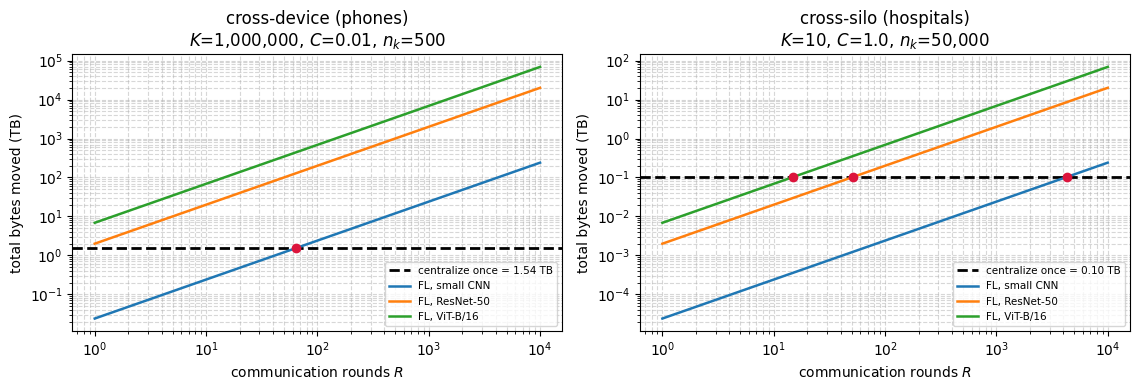

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.0))

R_grid = np.arange(1, 10_001)
for a, (sname, K, n_k, b_ex, C) in zip(ax, scenarios):
    bc = b_central(K, n_k, b_ex)
    a.axhline(bc / 1e12, color="k", ls="--", lw=2,
              label=f"centralize once = {bc / 1e12:.2f} TB")
    for mname, P in models:
        a.loglog(R_grid, b_fed(R_grid, K, C, P) / 1e12, lw=1.8, label=f"FL, {mname}")
        xo = crossover_rounds(K, n_k, b_ex, C, P)
        if 1 <= xo <= R_grid[-1]:
            a.plot([xo], [bc / 1e12], "o", ms=6, color="crimson", zorder=5)
    a.set_xlabel("communication rounds $R$")
    a.set_ylabel("total bytes moved (TB)")
    a.set_title(f"{sname}\n$K$={K:,}, $C$={C}, $n_k$={n_k:,}")
    a.legend(fontsize=7.5, loc="lower right")
    a.grid(True, ls="--", alpha=0.5, which="both")

plt.tight_layout()
print("red dots = crossover. Left of a dot, FL has moved fewer bytes; right of it, more.")

> **Observe:** the two panels differ in degree, not in direction.
>
> In the **cross-device** panel the crossover lands at a few dozen rounds for the
> small CNN and **below one round** for ResNet-50 and ViT-B/16 — meaning a *single*
> round of federated ResNet-50 across 1% of a million phones moves more bytes than
> shipping every photo to the datacentre would have. FL runs hundreds of rounds. So at
> cross-device scale, **FL is not a bandwidth optimization. It is strictly worse on
> bytes, and you do it anyway**, because the centralized dataset is not allowed to
> exist. Privacy and regulation are paying for that bandwidth, knowingly.
>
> The **cross-silo** panel only partly reverses this. Each hospital holds about 10 GB,
> so for the **small CNN** the crossover is about 4,000 rounds. Here FL really does move
> fewer bytes. But the advantage shrinks as the model grows: ResNet-50 crosses over at
> about 50 rounds and ViT-B/16 at about 15. A run of a few hundred rounds is worse on
> bytes for both. So the bandwidth argument holds in cross-silo **only for models that
> are small compared with each silo's data**. Even then, it is not why anyone built
> the system.
>
> Two things follow. First, **state your motivation honestly in your proposal**: if it
> is governance, say governance, and do not smuggle in a bandwidth claim you have not
> computed. Second, this is exactly why **Week 10 exists**: quantization and
> sparsification attack the $|\theta|$ in $B_{\text{fed}}$, and now you can see that
> they are not a nice-to-have at cross-device scale — they are what makes the bill
> payable at all.


### The two axes that classify an FL problem

Before designing an FL experiment, identify who the clients are.

**Axis 1 — who are the clients?**

|  | Cross-device | Cross-silo |
|---|---|---|
| Clients | Many phones, sensors, or browsers | A few hospitals, banks, or companies |
| Data per client | Usually small and unequal | Usually large and unequal |
| Availability | Devices come and go | Clients are usually available |
| Participation | A small fraction each round | Often all clients |
| Client state | Keeping state across rounds can be difficult | Keeping state is usually practical |
| Main challenges | Communication, dropout, scale | Compute, coordination, data governance |
| Example | Gboard next-word prediction | Training across hospitals |

Can the algorithm remember each client? This matters more than it first appears.

SCAFFOLD (Week 9) maintains a correction term for each client across rounds. That is straightforward when the same hospitals participate repeatedly. It is harder when millions of devices participate rarely and may lose their local state.

An algorithm’s state requirements must match the federation where it will run.

**Axis 2 — how the data is divided?**

|  | Horizontal FL | Vertical FL |
|---|---|---|
| Same across clients | Features | Some or all sample identities |
| Different across clients | Samples | Features |
| Data matrix | Split by rows | Split by columns |
| Example | Hospitals with the same tests but different patients | A bank and insurer with the same customers but different records |
| Labels | Usually held locally | Often held by one client |
| Match records across clients? | Usually unnecessary | Usually required |
| Training | Local training, then model aggregation | Joint training using features held by different clients |

This course focuses on horizontal FL. FedAvg, FedProx, SCAFFOLD, and the lab code assume this setting.

Vertical FL needs a different training protocol: clients must combine information from their separate features, often by exchanging protected intermediate results.

If your proposal uses vertical FL, state that on slide 1. The course concepts remain useful, but the training code and communication model will need substantial changes.


---

## 2. What FL actually adds to Local SGD

Week 7 showed the link between Local SGD and FedAvg: clients train locally, then
average their models. What changes in FL is the setting.

Suppose there are $K$ clients. Client $k$ holds $n_k$ examples, with
$n = \sum_k n_k$ examples in total. Each client takes $\tau$ local SGD steps per round:

$$\theta^{t+1} = \sum_{k=1}^{K} \frac{n_k}{n}\,\theta_k^{t,\tau}
\qquad\text{(FedAvg)}$$

At $\tau = 1$, full participation, and data-proportional weights, expand it:

$$\sum_k \frac{n_k}{n}\left(\theta^t - \eta g_k\right)
= \theta^t - \eta \sum_k \frac{n_k}{n} g_k
= \theta^t - \eta\, \nabla L(\theta^t)$$

which is exactly synchronous data-parallel SGD — the AllReduce you built in Week 5.
**FedAvg is not analogous to Local SGD; with full participation and data-proportional weights it *is* Local SGD — and at $\tau = 1$ both reduce to synchronous data-parallel SGD.**

**IID** means every client’s data comes from the same distribution—like shuffling one dataset and dividing it among clients. At the same model parameters, each client’s gradient is an unbiased estimate of the global gradient.

**Non-IID** means clients have different data distributions. One phone may contain mostly cat photos; one hospital may mainly treat a particular disease. Their gradients can point in different directions, causing local models to move apart (client drift, Week 9).

Clients may differ in labels, features, or dataset size. Unequal sizes alone do not imply different distributions. §8 uses a Dirichlet parameter $\alpha$ to control label skew: smaller $\alpha$ generally means more skew.

So FL is defined by the conditions it *drops*. Here they are, and the whole rest of the
course is one column of this table:

| assumption | distributed training | federated learning | when it breaks |
|---|---|---|---|
| $\tau = 1$ | yes — sync every step | **no**, $\tau \gg 1$ | Week 7: drift vs communication |
| data is IID across workers | **you shuffled it** | **no** — clients are people | Weeks 9, 11 |
| $n_k$ equal | by construction | **no** — hence the $n_k/n$ weights | today, Ex. 1 |
| all workers participate | yes | **no** — a random $C$-slice | Week 10 |
| workers are identical | same GPUs, same datacentre | **no** — a 2015 phone and a 2024 phone | Week 10 (stragglers) |
| workers are trusted | yes, you own them | **no** | Weeks 12–13 |
| data is inspectable | yes — you can look at it | **no** — you cannot even debug it | everywhere |

That last row has no algorithm attached to it and it may be the hardest one. In every
previous week, when a loss curve looked wrong you *looked at the data*. In FL you may
not. Your proposal's evaluation plan has to work without that.

Before we drop anything, let us re-verify the identity itself — in *this* notebook, on
*these* parameters — because everything that follows is a departure from it and a
departure from an unverified baseline is worth nothing.


In [4]:
# Week 7's hinge, re-checked on a fresh toy problem: at tau=1, full participation,
# and n_k/n weights, FedAvg's parameter average IS data-parallel SGD's gradient average.
d = 50
rk = np.random.default_rng(0)
theta_t = jnp.asarray(rk.normal(size=d))
eta = 0.05
sizes_id = np.array([37, 112, 64, 9, 200])
Xc = [jnp.asarray(rk.normal(size=(int(n), d))) for n in sizes_id]
Yc = [jnp.asarray(rk.normal(size=int(n))) for n in sizes_id]

def grad_k(theta, X, Y):
    return 2.0 * X.T @ (X @ theta - Y) / X.shape[0]        # grad of mean squared error

w_id = jnp.asarray(sizes_id / sizes_id.sum())

# (a) data-parallel SGD: average the GRADIENTS, then take one step
g_bar = sum(w_id[k] * grad_k(theta_t, Xc[k], Yc[k]) for k in range(len(sizes_id)))
dp_sgd = theta_t - eta * g_bar

# (b) FedAvg with tau=1: each client takes its OWN step, server averages the PARAMETERS
locals_1 = [theta_t - eta * grad_k(theta_t, Xc[k], Yc[k]) for k in range(len(sizes_id))]
fedavg = sum(w_id[k] * locals_1[k] for k in range(len(sizes_id)))

gap = float(jnp.max(jnp.abs(dp_sgd - fedavg)))
rel = gap / float(jnp.max(jnp.abs(dp_sgd)))
print("(a) data-parallel SGD : theta - eta * sum_k (n_k/n) g_k")
print("(b) FedAvg at tau=1   : sum_k (n_k/n) (theta - eta g_k)")
print(f"\nmax |a - b| = {gap:.3e}   (relative {rel:.3e})   <- the SAME UPDATE, to float32 round-off (~1e-7)")
print("Equal up to float32 round-off -- it is one application of linearity.")
print()
# and it breaks the moment tau > 1
def local_tau(theta, X, Y, tau):
    for _ in range(tau):
        theta = theta - eta * grad_k(theta, X, Y)
    return theta

print(f"{'tau':>5}  {'max |FedAvg - dp-SGD-tau-steps|':>32}")
print("-" * 40)
for tau in [1, 2, 5, 20]:
    fed = sum(w_id[k] * local_tau(theta_t, Xc[k], Yc[k], tau) for k in range(len(sizes_id)))
    # the honest comparison: tau steps of the AVERAGED gradient (i.e. no drift)
    cen = theta_t
    for _ in range(tau):
        cen = cen - eta * sum(w_id[k] * grad_k(cen, Xc[k], Yc[k]) for k in range(len(sizes_id)))
    print(f"{tau:>5}  {float(jnp.max(jnp.abs(fed - cen))):>32.3e}")
print("\ntau=1: round-off only (~1e-7). tau>1: a gap that GROWS. That gap is client drift, it is the price")
print("of communicating 1/tau as often, and it is what Weeks 7 and 9 are about.")

(a) data-parallel SGD : theta - eta * sum_k (n_k/n) g_k
(b) FedAvg at tau=1   : sum_k (n_k/n) (theta - eta g_k)

max |a - b| = 1.192e-07   (relative 5.657e-08)   <- the SAME UPDATE, to float32 round-off (~1e-7)
Equal up to float32 round-off -- it is one application of linearity.

  tau   max |FedAvg - dp-SGD-tau-steps|
----------------------------------------
    1                         1.192e-07
    2                         1.124e-02
    5                         7.331e-02
   20                         3.340e-01

tau=1: round-off only (~1e-7). tau>1: a gap that GROWS. That gap is client drift, it is the price
of communicating 1/tau as often, and it is what Weeks 7 and 9 are about.


> **Observe:** at $\tau = 1$ the two updates agree to **float32 round-off** (~1e-7),
> not a real gap. FedAvg and data-parallel SGD are the same arithmetic, and the $n_k/n$ weights
> are exactly what makes the identity hold with unequal shards. The moment $\tau > 1$ the
> gap opens and grows with $\tau$: each client is now descending *its own* objective for
> several steps, and the average of the five clients' separately-drifted models is not the
> point you would have reached by taking $\tau$ steps along the averaged gradient. Everything else in this notebook
> is plumbing; **that gap is the science**, and Week 9 attacks it directly.


Now let us make the dropped assumptions quantitative, on a problem small enough to see
through.


In [5]:
# A deliberately transparent problem: per-client linear least squares, so we can compute
# the exact global optimum and measure "wrong" as a number rather than a vibe.
D = 20
K = 8

def make_clients(seed, n_k, heterogeneity=0.0):
    # Each client k has data from theta_k = theta_star + heterogeneity * delta_k.
    # heterogeneity = 0 -> IID.  Large -> clients disagree about the answer.
    r = np.random.default_rng(seed)
    theta_star = r.normal(size=D)
    Xs, Ys, thetas = [], [], []
    for k in range(len(n_k)):
        theta_k = theta_star + heterogeneity * r.normal(size=D)
        Xk = r.normal(size=(n_k[k], D))
        Yk = Xk @ theta_k + 0.1 * r.normal(size=n_k[k])
        Xs.append(Xk); Ys.append(Yk); thetas.append(theta_k)
    return Xs, Ys, theta_star

def global_opt(Xs, Ys):
    # The answer FL is TRYING to approximate: least squares on the pooled data.
    X = np.concatenate(Xs); Y = np.concatenate(Ys)
    return np.linalg.lstsq(X, Y, rcond=None)[0]

def local_opt(Xk, Yk):
    return np.linalg.lstsq(Xk, Yk, rcond=None)[0]


n_k = np.array([100] * K)                      # equal sizes, for now
Xs, Ys, theta_star = make_clients(0, n_k, heterogeneity=0.0)

theta_global = global_opt(Xs, Ys)
locals_ = np.stack([local_opt(Xs[k], Ys[k]) for k in range(K)])

# Averaging fully converged local solutions is ONE-SHOT averaging: FedAvg with a single
# round and tau -> infinity. It isolates the aggregation weights from everything else.
w = n_k / n_k.sum()
agg_weighted = w @ locals_
agg_uniform = locals_.mean(axis=0)

print(f"{'aggregation':>34}  {'||agg - theta_global||':>22}")
print("-" * 60)
print(f"{'sum_k (n_k/n) theta_k  (weighted)':>34}  {np.linalg.norm(agg_weighted - theta_global):>22.6f}")
print(f"{'uniform mean':>34}  {np.linalg.norm(agg_uniform - theta_global):>22.6f}")
print(f"\nequal n_k -> the two weightings are IDENTICAL: "
      f"{np.allclose(agg_weighted, agg_uniform)}")
print("With equal shards the n_k/n weight is invisible. That is exactly why people")
print("forget it -- and why it only bites once client sizes stop being equal.")
print("(Local optima averaged once = one-shot FedAvg, tau -> infinity.)")

                       aggregation  ||agg - theta_global||
------------------------------------------------------------
 sum_k (n_k/n) theta_k  (weighted)                0.007054
                      uniform mean                0.007054

equal n_k -> the two weightings are IDENTICAL: True
With equal shards the n_k/n weight is invisible. That is exactly why people
forget it -- and why it only bites once client sizes stop being equal.
(Local optima averaged once = one-shot FedAvg, tau -> infinity.)


### 🔬 Exercise 1

**Exercise:** make the client sizes unequal and find out what the $n_k/n$ weight is
worth. Sweep an imbalance factor: client sizes $n_k \propto \rho^k$ for
$\rho \in [1, 3]$, and at each $\rho$ compute the distance to the pooled optimum for
(a) the uniform mean and (b) the $n_k/n$-weighted mean.

Then do the *second* experiment, which is the one that matters: hold sizes **equal**
and turn on **heterogeneity** instead (clients disagreeing about $\theta$). Which
failure does the $n_k/n$ weight fix, and which does it not touch at all?


(a) at imbalance 2187x : uniform err 0.0186 vs weighted 0.0001  ->  356.8x worse
(b) at heterogeneity 1.0: uniform err 0.6472 vs weighted 0.6472  ->  the two curves LIE ON TOP OF EACH OTHER


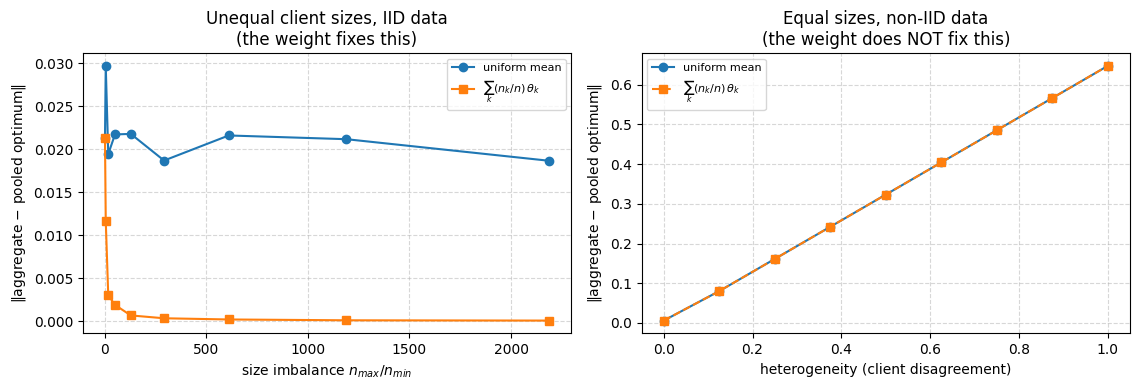

In [6]:
# --- Reference solution (instructor: blank this out for students) ---

# (a) unequal sizes, IID data
rhos = np.linspace(1.0, 3.0, 9)
err_uni, err_wtd, imbalance = [], [], []
for rho in rhos:
    nk = np.array([int(40 * rho ** k) for k in range(K)])
    Xs_, Ys_, _ = make_clients(1, nk, heterogeneity=0.0)
    tg = global_opt(Xs_, Ys_)
    loc = np.stack([local_opt(Xs_[k], Ys_[k]) for k in range(K)])
    err_uni.append(np.linalg.norm(loc.mean(axis=0) - tg))
    err_wtd.append(np.linalg.norm((nk / nk.sum()) @ loc - tg))
    imbalance.append(nk.max() / nk.min())

# (b) equal sizes, non-IID data
hets = np.linspace(0.0, 1.0, 9)
err_uni_h, err_wtd_h = [], []
nk_eq = np.array([100] * K)
for h in hets:
    Xs_, Ys_, _ = make_clients(2, nk_eq, heterogeneity=h)
    tg = global_opt(Xs_, Ys_)
    loc = np.stack([local_opt(Xs_[k], Ys_[k]) for k in range(K)])
    err_uni_h.append(np.linalg.norm(loc.mean(axis=0) - tg))
    err_wtd_h.append(np.linalg.norm((nk_eq / nk_eq.sum()) @ loc - tg))

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.0))
ax[0].plot(imbalance, err_uni, "o-", label="uniform mean")
ax[0].plot(imbalance, err_wtd, "s-", label="$\\sum_k (n_k/n)\\,\\theta_k$")
ax[0].set_xlabel("size imbalance $n_{max}/n_{min}$")
ax[0].set_ylabel("$\\|$aggregate $-$ pooled optimum$\\|$")
ax[0].set_title("Unequal client sizes, IID data\n(the weight fixes this)")
ax[0].legend(fontsize=8); ax[0].grid(True, ls="--", alpha=0.5)

ax[1].plot(hets, err_uni_h, "o-", label="uniform mean")
ax[1].plot(hets, err_wtd_h, "s--", label="$\\sum_k (n_k/n)\\,\\theta_k$")
ax[1].set_xlabel("heterogeneity (client disagreement)")
ax[1].set_ylabel("$\\|$aggregate $-$ pooled optimum$\\|$")
ax[1].set_title("Equal sizes, non-IID data\n(the weight does NOT fix this)")
ax[1].legend(fontsize=8); ax[1].grid(True, ls="--", alpha=0.5)
plt.tight_layout()

print(f"(a) at imbalance {imbalance[-1]:.0f}x : uniform err {err_uni[-1]:.4f} "
      f"vs weighted {err_wtd[-1]:.4f}  ->  {err_uni[-1] / max(err_wtd[-1], 1e-12):.1f}x worse")
print(f"(b) at heterogeneity {hets[-1]:.1f}: uniform err {err_uni_h[-1]:.4f} "
      f"vs weighted {err_wtd_h[-1]:.4f}  ->  the two curves LIE ON TOP OF EACH OTHER")

> **Observe:** two different failures that people routinely confuse.
>
> **Left:** unequal sizes. At the extreme the uniform mean gives a client with 40
> examples the same vote as one with 87,000, and the error grows with imbalance while the
> $n_k/n$-weighted mean stays near the pooled optimum. This is the failure FedAvg's
> weight was designed for, and it is a *bookkeeping* error — the right answer is
> available, you just have to count.
>
> **Right:** equal sizes, non-IID data. The two curves are **identical**, and both
> climb. With equal $n_k$ the weight $n_k/n = 1/K$ *is* the uniform mean, so it cannot
> possibly help — and the error grows anyway, because the average of the clients'
> optima is not the optimum of the pooled data once the clients disagree. Averaging
> minimizers is not the same as minimizing the average, and no *scalar* reweighting fixes
> that in general. (In this linear toy problem, weighting each local solution by the
> matrix $X_k^\top X_k$ would recover the pooled optimum exactly; that trick does not
> carry over to neural networks.)
>
> That gap is **client drift**, it is the single hardest thing in federated
> optimization, and it is Week 9's entire subject. Notice what today's notebook can and
> cannot do about it: the $n_k/n$ weight is a *plumbing* correctness property, and we
> will verify it exactly in §6. Drift is a *mathematical* problem and needs FedProx or
> SCAFFOLD. **Do not confuse a plumbing bug with a research finding** — the most common
> way to "discover" client drift is to have forgotten the weight.


---

## 3. The four states, at the boundary

Since Week 3 this codebase has kept four pieces of state deliberately apart:
**model parameters · optimizer state · batch statistics · PRNG state**. The notebooks
have asked for that separation every week, and until now it has been fair to wonder
whether it was worth the extra bookkeeping.

This is the week it pays. A federated round has to decide, **for each of the four
separately**, whether it crosses the wire, in which direction, and what happens to it
between rounds. If your states are fused into one blob, that decision cannot be
expressed — and the FL transition turns into a rewrite.

| state | what it is | crosses the wire? | lifetime |
|---|---|---|---|
| **parameters $\theta$** | the thing being learned | **yes, both ways** — down each round, up each round | global; this *is* the model |
| **optimizer state** | Optax momentum / Adam moments | **no** — client-local | **discarded** at the end of every round (cross-device; stateful silos may keep it) |
| **batch statistics** | BatchNorm running mean/var | *usually yes*, bundled with params — but see below | global by default |
| **PRNG key** | randomness | **no** — derived, never shipped | `fold_in(fold_in(master, round), cid)` |

Three of those rows deserve an argument rather than an assertion.

**Optimizer state is client-local, and it is thrown away.** Momentum is a property of a
*trajectory*, and in cross-device FL a client's trajectory is $\tau$ steps long and then
that client is gone forever. There is no trajectory for the momentum to be about.
(In cross-silo FL the same silos return every round, so keeping local optimizer state
across rounds is a legitimate choice there — the statefulness axis again.) Ship
it and you are shipping $2\times$ or $3\times$ the bytes to communicate a running
average of five gradients from a machine you will never see again. (The *server* may
run its own optimizer over the aggregate — that is FedAvgM / FedAdam, and its state is
server-side and persistent. Different object, different lifetime. Do not conflate them.)

**Batch statistics are not parameters, they are data.** BatchNorm's running mean and
variance are summary statistics *of the client's input distribution*. Under **feature
shift** — clients whose inputs look different, such as images from different scanners —
they are exactly the thing that differs between clients, so averaging them averages
incompatible distributions. (Under pure label skew they barely move; Exercise 2 measures
both.) **FedBN** (Week 11) keeps the whole BatchNorm layer local — these statistics *and*
the affine $\gamma, \beta$ — for precisely this reason, and under feature shift it is a
strong personalization baseline for approximately zero effort. This is only a decision
you can *make* because they are a separate PyTree.

**PRNG state is derived, never transmitted.** Week 4 built this: `fold_in(fold_in(master,
round), cid)` gives every (round, client) pair an independent, reproducible stream with
no coordination and no bytes on the wire. A client does not need to be *told* its
randomness; it needs to be told its ID.


In [7]:
# ---- The Stage 1-3 codebase, carried across unchanged (Weeks 3-7) ----
N_CLASSES, IMG = 4, 32

class ResBlock(eqx.Module):
    conv1: eqx.nn.Conv2d
    bn1: eqx.nn.BatchNorm
    conv2: eqx.nn.Conv2d
    bn2: eqx.nn.BatchNorm

    def __init__(self, channels, key, bn_momentum=0.9):
        k1, k2 = jax.random.split(key)
        self.conv1 = eqx.nn.Conv2d(channels, channels, 3, padding=1, use_bias=False, key=k1)
        self.bn1 = eqx.nn.BatchNorm(channels, axis_name="batch", mode="batch", momentum=bn_momentum)
        self.conv2 = eqx.nn.Conv2d(channels, channels, 3, padding=1, use_bias=False, key=k2)
        self.bn2 = eqx.nn.BatchNorm(channels, axis_name="batch", mode="batch", momentum=bn_momentum)

    def __call__(self, x, state):
        h, state = self.bn1(self.conv1(x), state)
        h = jax.nn.relu(h)
        h, state = self.bn2(self.conv2(h), state)
        return jax.nn.relu(x + h), state


class ResNet(eqx.Module):
    stem: eqx.nn.Conv2d
    stem_bn: eqx.nn.BatchNorm
    blocks: list
    head: eqx.nn.Linear

    def __init__(self, key, channels=8, n_blocks=1, n_classes=N_CLASSES, bn_momentum=0.9):
        ks = jax.random.split(key, n_blocks + 2)
        self.stem = eqx.nn.Conv2d(3, channels, 3, stride=2, padding=1, use_bias=False, key=ks[0])
        self.stem_bn = eqx.nn.BatchNorm(channels, axis_name="batch", mode="batch",
                                        momentum=bn_momentum)
        self.blocks = [ResBlock(channels, ks[i + 1], bn_momentum) for i in range(n_blocks)]
        self.head = eqx.nn.Linear(channels, n_classes, key=ks[-1])

    def __call__(self, x, state):
        x, state = self.stem_bn(self.stem(x), state)
        x = jax.nn.relu(x)
        for block in self.blocks:
            x, state = block(x, state)
        x = jnp.mean(x, axis=(1, 2))
        return self.head(x), state


def batched_forward(model, state, x):
    return eqx.filter_vmap(lambda m, s, xi: m(xi, s), in_axes=(None, None, 0),
                           out_axes=(0, None), axis_name="batch")(model, state, x)


# ---- Week 3's synthetic CIFAR-shaped data (the harness has no network; the real lab
#      points at CIFAR-10 through Grain on the GPU node) ----
def make_templates(key, n_classes=N_CLASSES, size=IMG):
    lo = jax.random.normal(key, (n_classes, 3, 8, 8))
    return jax.image.resize(lo, (n_classes, 3, size, size), method="linear")


def make_data(n, key, templates, noise=1.0):
    k_lab, k_noise = jax.random.split(key)
    labels = jax.random.randint(k_lab, (n,), 0, templates.shape[0])
    noise_arr = jax.random.normal(k_noise, (n,) + templates.shape[1:]) * noise
    return templates[labels] + noise_arr, labels


TEMPLATES = make_templates(jax.random.key(7))

# ---- The four states, still four, still separate ----
model0, bn0 = eqx.nn.make_with_state(ResNet)(jax.random.key(1))   # 1. params  2. batch stats
params0, static0 = eqx.partition(model0, eqx.is_inexact_array)
optimizer = optax.sgd(5e-2, momentum=0.9)
opt0 = optimizer.init(params0)                                    # 3. optimizer state
master_key = jax.random.key(2024)                                 # 4. PRNG

from jax.flatten_util import ravel_pytree
flat_params, _ = ravel_pytree(params0)
flat_opt, _ = ravel_pytree(opt0)
flat_bn, _ = ravel_pytree(bn0)

print(f"{'state':>18}  {'leaves':>7}  {'elements':>9}  {'KiB':>11}  {'ships?':>8}")
print("-" * 62)
for name, tree, ships in [("parameters", params0, "YES"), ("optimizer state", opt0, "no"),
                          ("batch stats", bn0, "bundled"), ("PRNG key", master_key, "no")]:
    # a typed PRNG key is not a float array; measure its raw uint32 words instead
    fl_ = jax.random.key_data(tree).ravel() if name == "PRNG key" else ravel_pytree(tree)[0]
    n_leaves = len(jax.tree.leaves(tree))
    print(f"{name:>18}  {n_leaves:>7}  {fl_.size:>9,}  {fl_.nbytes / 1024:>11.2f}  {ships:>8}")
print()
print(f"per-round upload if you ship params only : {flat_params.nbytes / 1024:.2f} KiB")
print(f"per-round upload if you ship params + SGD-momentum state: "
      f"{(flat_params.nbytes + flat_opt.nbytes) / 1024:.2f} KiB  "
      f"({(flat_params.nbytes + flat_opt.nbytes) / flat_params.nbytes:.1f}x)")
print("Adam would be 3x. Every byte of it communicates a five-step running average from")
print("a client you will never meet again (in cross-device FL).")

             state   leaves   elements          KiB    ships?
--------------------------------------------------------------
        parameters       11      1,452         5.67       YES
   optimizer state       11      1,452         5.67        no
       batch stats        9         51         0.20   bundled
          PRNG key        1          2         0.01        no

per-round upload if you ship params only : 5.67 KiB
per-round upload if you ship params + SGD-momentum state: 11.34 KiB  (2.0x)
Adam would be 3x. Every byte of it communicates a five-step running average from
a client you will never meet again (in cross-device FL).


> **Observe:** Momentum adds roughly one model's worth of state; Adam adds two. Sending it
> with the parameters would roughly double or triple the payload, only for §7's clients to
> reset it with `optimizer.init(params)` each round. Keeping the four states separate lets
> us send only what the round needs.


---

## 4. The transport boundary: PyTree → NumPy → `Parameters` → back

Flower knows nothing about JAX. Its wire format is a list of **NumPy arrays**, which it
serializes to bytes and back:

```
     server (your code)                Flower                client (your code)
┌─────────────────────────┐                             ┌─────────────────────────┐
│ build_model()           │                             │ build_model()           │
│   └─► treedef           │                             │   └─► treedef           │
│       (kept here)       │                             │       (kept here)       │
│                         │                             │                         │
│ params ──flatten──►     │   ── ndarrays ⇄ bytes ──►   │ ──unflatten──► params   │
│ params ◄─unflatten──    │   ◄── ndarrays ⇄ bytes ──   │ ◄──flatten──── params   │
└─────────────────────────┘                             └─────────────────────────┘

  your code:  flatten   = eqx.partition → jax.tree.leaves → np.asarray
              unflatten = jnp.asarray → jax.tree.unflatten(LOCAL treedef, leaves)
  Flower:     ndarrays_to_parameters → Parameters(bytes) → parameters_to_ndarrays

  Same code ⇒ same treedef on both sides. Only the ordered leaves cross the wire.
  Flower never sees the treedef and never checks the order.
```

Three rules keep serialization correct:

1. **Send only array leaves.** Both sides rebuild the model from the same code. In §7,
   pickling an Equinox treedef or a notebook-defined `Module` into Ray fails. Workers
   need model code they can import.
2. **Match the leaf order.** Leaf $i$ must represent the same array on both sides. The
   payload carries no names, so we must check the structure and order ourselves.
3. **Convert explicitly.** Use `np.asarray` before sending and `jnp.asarray` after
   receiving. Check shapes and dtypes for unwanted changes.

Now build the round trip and check exact equality.


In [8]:
from flwr.common import ndarrays_to_parameters, parameters_to_ndarrays

# ---------- the three functions that ARE the glue layer ----------
# Only PARAMETERS cross here. bn_state is built but not shipped: under mode="batch"
# the BN running buffers are inert in this notebook (see §3's honesty check). A model
# that uses mode="ema" at inference must decide explicitly: ship them, or keep them
# local (FedBN, Week 11).

def build_model(seed=1):
    # Both server and client call this. It is the shared contract: same code, same
    # treedef, same leaf order, on every machine. Nothing about it crosses the wire.
    model, bn_state = eqx.nn.make_with_state(ResNet)(jax.random.key(seed))
    params, static = eqx.partition(model, eqx.is_inexact_array)
    return params, static, bn_state


def params_to_ndarrays(params):
    # JAX PyTree -> list[np.ndarray]. np.asarray pulls off the device into host RAM.
    return [np.asarray(leaf) for leaf in jax.tree.leaves(params)]


def ndarrays_to_params(template, ndarrays, check=True):
    # list[np.ndarray] -> JAX PyTree, using a LOCALLY reconstructed treedef.
    # check=True compares count, shape and dtype with the local template (rules 2 and 3).
    # It catches a wrong architecture or a float64 payload. It CANNOT catch two leaves of
    # the same shape swapped -- see the failures below.
    if check:
        expected = jax.tree.leaves(template)
        if len(ndarrays) != len(expected):
            raise ValueError(f"leaf count: got {len(ndarrays)}, template has {len(expected)}")
        for i, (a, t) in enumerate(zip(ndarrays, expected)):
            if a.shape != t.shape or a.dtype != t.dtype:
                raise ValueError(f"leaf {i}: got {a.shape} {a.dtype}, "
                                 f"expected {t.shape} {t.dtype}")
    treedef = jax.tree.structure(template)
    return jax.tree.unflatten(treedef, [jnp.asarray(a) for a in ndarrays])


# ---------- the round trip ----------
nds = params_to_ndarrays(params0)
print(f"{'#':>3}  {'shape':>22}  {'dtype':>9}  {'KiB':>7}")
print("-" * 48)
for i, a in enumerate(nds):
    print(f"{i:>3}  {str(a.shape):>22}  {str(a.dtype):>9}  {a.nbytes / 1024:>7.2f}")
print(f"\n{len(nds)} tensors, {sum(a.size for a in nds):,} floats, "
      f"{sum(a.nbytes for a in nds) / 1024:.2f} KiB")

# into Flower's wire type and back out
parameters = ndarrays_to_parameters(nds)
print(f"\nflwr Parameters: tensor_type={parameters.tensor_type!r}, "
      f"{len(parameters.tensors)} serialized tensors, "
      f"{sum(len(t) for t in parameters.tensors) / 1024:.2f} KiB on the wire")

nds_back = parameters_to_ndarrays(parameters)
template, _, _ = build_model()                     # rebuilt from CODE, not from bytes
params_back = ndarrays_to_params(template, nds_back)

# ---------- prove it ----------
same_struct = jax.tree.structure(params0) == jax.tree.structure(params_back)
bitwise = all(bool(jnp.all(a == b))
              for a, b in zip(jax.tree.leaves(params0), jax.tree.leaves(params_back)))
maxdiff = max(float(jnp.max(jnp.abs(a - b)))
              for a, b in zip(jax.tree.leaves(params0), jax.tree.leaves(params_back)))
print(f"\ntreedef preserved : {same_struct}")
print(f"BITWISE identical : {bitwise}   (max |diff| = {maxdiff:.1e})")
print("Not 'close'. IDENTICAL. float32 -> bytes -> float32 is lossless, and if your")
print("round trip is merely close to 1e-7, something is casting and you should find it.")

  #                   shape      dtype      KiB
------------------------------------------------
  0            (8, 3, 3, 3)    float32     0.84
  1                    (8,)    float32     0.03
  2                    (8,)    float32     0.03
  3            (8, 8, 3, 3)    float32     2.25
  4                    (8,)    float32     0.03
  5                    (8,)    float32     0.03
  6            (8, 8, 3, 3)    float32     2.25
  7                    (8,)    float32     0.03
  8                    (8,)    float32     0.03
  9                  (4, 8)    float32     0.12
 10                    (4,)    float32     0.02

11 tensors, 1,452 floats, 5.67 KiB

flwr Parameters: tensor_type='numpy.ndarray', 11 serialized tensors, 7.05 KiB on the wire

treedef preserved : True
BITWISE identical : True   (max |diff| = 0.0e+00)
Not 'close'. IDENTICAL. float32 -> bytes -> float32 is lossless, and if your
round trip is merely close to 1e-7, something is casting and you should find it.


### What breaks: the three failures, on purpose

The round trip above is exact, which makes it useless as a teacher. Let us break it the
three ways it breaks in practice.


In [9]:
# ---- Failure 1 (LOUD): the client built a tree with a different number of leaves.
deep_model, _ = eqx.nn.make_with_state(ResNet)(jax.random.key(1), n_blocks=2)   # 2 blocks, not 1
deep_params, _ = eqx.partition(deep_model, eqx.is_inexact_array)
print(f"server tree: {len(jax.tree.leaves(params0))} leaves | "
      f"client tree: {len(jax.tree.leaves(deep_params))} leaves")
try:
    ndarrays_to_params(deep_params, nds, check=False)       # raw unflatten, no validation
    print("Failure 1: no error?!")
except ValueError as e:
    print("Failure 1 -- client built n_blocks=2, server sent n_blocks=1 tensors:")
    print("   ValueError:", str(e).split(chr(10))[0][:95])
    print("   ^ We got LUCKY: the ARITY differed, so unflatten refused. This is the")
    print("     friendly failure. The next two are not friendly.")

# ---- Failure 1b (SILENT UNTIL IT RUNS): same leaf count, wrong shapes.
wide_model, _ = eqx.nn.make_with_state(ResNet)(jax.random.key(1), channels=16)  # 16, not 8
wide_params, _ = eqx.partition(wide_model, eqx.is_inexact_array)
print(f"\nFailure 1b -- client built channels=16: "
      f"{len(jax.tree.leaves(wide_params))} leaves -- the SAME count as the server's "
      f"{len(nds)}.")
mismatched = ndarrays_to_params(wide_params, nds, check=False)   # unflatten checks COUNT, not shape
print(f"   unflatten raised? NO. It only checks the NUMBER of leaves, never the shapes.")
print(f"   the tree now holds channels=8 arrays inside a 'channels=16' model:")
print(f"     leaf 0 shape {jax.tree.leaves(mismatched)[0].shape} "
      f"(the client expected {jax.tree.leaves(wide_params)[0].shape})")
wide_static = eqx.partition(wide_model, eqx.is_inexact_array)[1]
out_w, _ = batched_forward(eqx.combine(mismatched, wide_static), bn0,
                           jnp.zeros((2, 3, IMG, IMG)))
print(f"   forward pass raised? NO -- it ran and returned {out_w.shape}.")
print("   ^ Silent as well, and for an instructive reason: `channels` lives in the")
print("     STATIC half as metadata, but the convolution just uses whatever weight")
print("     array it was handed. The client asked for a 16-channel model and is now")
print("     quietly running an 8-channel one. The static half is not a type check.")

# ---- Failure 1c (SILENT, FOREVER): same count, same shapes, different MEANING.
# leaves 1 and 2 are both (8,) -- BatchNorm weight and bias. Swap them.
print(f"\nFailure 1c -- leaves 1 and 2 both have shape {nds[1].shape}. Swap them on the wire:")
shuffled = [nds[0], nds[2], nds[1]] + nds[3:]
bad = ndarrays_to_params(template, shuffled, check=False)
ok = all(bool(jnp.all(a == b)) for a, b in zip(jax.tree.leaves(params0), jax.tree.leaves(bad)))
out, _ = batched_forward(eqx.combine(bad, static0), bn0, jnp.zeros((2, 3, IMG, IMG)))
print(f"   unflatten raised? NO.   forward pass raised? NO (output {out.shape}).")
print(f"   parameters correct? {ok}")
print("   ^ THIS is the one to fear. A perfectly valid model with the wrong weights in")
print("     it. Order is the whole contract and NOTHING checks it.")

# ---- Failure 2: float64 sneaks in
f64 = [a.astype(np.float64) for a in nds]
p64 = ndarrays_to_params(template, f64, check=False)
dt = {str(l.dtype) for l in jax.tree.leaves(p64)}
print(f"\nFailure 2 -- a client returns float64: dtypes back in JAX = {dt}")
print(f"   bytes on the wire: {sum(a.nbytes for a in f64) / 1024:.2f} KiB "
      f"vs {sum(a.nbytes for a in nds) / 1024:.2f} KiB  <- 2x, for nothing")
print("   (jax_enable_x64 is off, so JAX silently demoted back to float32 -- the array")
print("    round-tripped fine and you paid double bandwidth. No error. Check your dtypes.)")

# ---- Failure 3: forgetting that `static` is not on the wire either
print(f"\nFailure 3 -- what is in `static0` (NOT shipped, NOT in `nds`):")
print(f"   {len(nds)} array leaves ship; static holds the non-array fields "
      f"(activations, flags, shapes).")
print("   eqx.combine(params, static) reassembles the model. `static` is CODE, so both")
print("   sides get it by calling build_model(). If you find yourself pickling `static`,")
print("   stop -- you have confused configuration with data.")

# ---- The defence: check=True (the default everywhere else in this notebook)
print("\nThe defence -- the same payloads through ndarrays_to_params(..., check=True):")
for name, tmpl, payload in [("1  n_blocks=2", deep_params, nds),
                            ("1b channels=16", wide_params, nds),
                            ("1c swapped leaves", template, shuffled),
                            ("2  float64", template, f64)]:
    try:
        ndarrays_to_params(tmpl, payload, check=True)
        print(f"   {name:<18}: passed the check   <- NOT caught")
    except ValueError as e:
        print(f"   {name:<18}: caught -- {e}")
print("   ^ count/shape/dtype checks catch 1, 1b and 2. They cannot catch 1c: the shapes")
print("     match, so only building both sides from the same build_model() prevents it.")

server tree: 11 leaves | client tree: 17 leaves
Failure 1 -- client built n_blocks=2, server sent n_blocks=1 tensors:
   ValueError: Too few leaves for PyTreeDef; expected 17, got 11
   ^ We got LUCKY: the ARITY differed, so unflatten refused. This is the
     friendly failure. The next two are not friendly.

Failure 1b -- client built channels=16: 11 leaves -- the SAME count as the server's 11.
   unflatten raised? NO. It only checks the NUMBER of leaves, never the shapes.
   the tree now holds channels=8 arrays inside a 'channels=16' model:
     leaf 0 shape (8, 3, 3, 3) (the client expected (16, 3, 3, 3))
   forward pass raised? NO -- it ran and returned (2, 4).
   ^ Silent as well, and for an instructive reason: `channels` lives in the
     STATIC half as metadata, but the convolution just uses whatever weight
     array it was handed. The client asked for a 16-channel model and is now
     quietly running an 8-channel one. The static half is not a type check.

Failure 1c -- leaves

> **Observe:** Swapping two same-shaped tensors silently puts the wrong weights into the
> model. Flower's `Parameters` carries no tensor names—only positions.
>
> Both sides should use the same `build_model()` and leaf traversal, rather than
> hand-written tensor lists. `ravel_pytree` offers a single flat vector, but hides the
> layer boundaries needed for per-layer quantization (Week 10) and norm filters
> (Week 13). We keep the tensor list so those operations remain straightforward.


### 🔬 Exercise 2 — What should cross the wire?

1. **Optimizer payload.** Write `optstate_to_ndarrays(opt_state)`. Measure the momentum
   state's bytes relative to the parameter payload, and verify an exact round trip.
2. **Momentum across clients.** Start two clients from identical parameters but give them
   different data. Run 5 local SGD-with-momentum steps. Compare the cosine similarity of
   their final momentum buffers with that of their final parameters. Does momentum
   transfer meaningfully between clients?
3. **Batch statistics under non-IID data.** Compare three settings:
   - **Baseline:** both clients sample the same distribution.
   - **Label skew:** clients see different classes.
   - **Feature shift:** clients see the same classes, but one client's inputs are rescaled.

   Measure how far their BatchNorm running statistics diverge relative to their
   parameters. What do the results suggest about averaging these statistics?

   Before interpreting the numbers, read the solution's final paragraph: the model's
   BatchNorm mode matters.


In [10]:
# --- Reference solution (instructor: blank this out for students) ---

def optstate_to_ndarrays(opt_state):
    return [np.asarray(l) for l in jax.tree.leaves(opt_state)]

# (1) cost
p_bytes = sum(a.nbytes for a in params_to_ndarrays(params0))
o_bytes = sum(a.nbytes for a in optstate_to_ndarrays(opt0))
print(f"(1) params {p_bytes / 1024:>7.2f} KiB | opt state {o_bytes / 1024:>7.2f} KiB "
      f"| shipping both = {(p_bytes + o_bytes) / p_bytes:.2f}x")
adam_state = optax.adam(1e-3).init(params0)
a_bytes = sum(a.nbytes for a in optstate_to_ndarrays(adam_state))
print(f"    with Adam instead: {(p_bytes + a_bytes) / p_bytes:.2f}x")

# (2) is momentum shareable? -- two clients, different data, same start
def loss_fn(params, static, state, x, y):
    logits, state = batched_forward(eqx.combine(params, static), state, x)
    return optax.softmax_cross_entropy_with_integer_labels(logits, y).mean(), state

@eqx.filter_jit
def step(params, state, opt_state, x, y, static):
    (l, state), g = jax.value_and_grad(loss_fn, has_aux=True)(params, static, state, x, y)
    upd, opt_state = optimizer.update(g, opt_state, params)
    return eqx.apply_updates(params, upd), state, opt_state, l

def cos(a, b):
    fa, _ = ravel_pytree(a); fb, _ = ravel_pytree(b)
    return float(fa @ fb / (jnp.linalg.norm(fa) * jnp.linalg.norm(fb) + 1e-12))

def run_client(seed, labels, scale=1.0, offset=0.0, steps=5):
    # 16 images with the given labels. scale/offset change the INPUT distribution
    # (a different scanner or camera): feature shift, as opposed to label skew.
    k = jax.random.fold_in(jax.random.key(0), seed)
    noise = jax.random.normal(k, (labels.shape[0], 3, IMG, IMG))
    x = (TEMPLATES[labels] + noise) * scale + offset
    p, s, o = params0, bn0, optimizer.init(params0)
    for _ in range(steps):
        p, s, o, _ = step(p, s, o, x, labels, static0)
    return p, s, o

only = lambda c: jnp.full((16,), c, dtype=jnp.int32)       # one class only
mixed = jnp.arange(16, dtype=jnp.int32) % N_CLASSES        # all classes, balanced

# Label skew: client A sees only class 0, client B only class 1 (Dirichlet alpha -> 0).
pA, sA, oA = run_client(0, only(0))
pB, sB, oB = run_client(1, only(1))
x_eval, y_eval = make_data(32, jax.random.key(99), TEMPLATES)

# (1, continued) round trip -- on a TRAINED momentum state (opt0 is all zeros, so a round
# trip of opt0 would pass trivially and prove nothing)
oA_back = jax.tree.unflatten(jax.tree.structure(oA),
                             [jnp.asarray(a) for a in optstate_to_ndarrays(oA)])
rt_exact = all(bool(jnp.all(a == b)) for a, b in zip(jax.tree.leaves(oA), jax.tree.leaves(oA_back)))
print(f"    round trip of client A's trained momentum state: exact = {rt_exact}")
print(f"\n(2) cos(params_A, params_B)     = {cos(pA, pB):>7.4f}  <- nearly 1: they share theta_0")
print(f"    cos(momentum_A, momentum_B) = {cos(oA, oB):>7.4f}  <- much lower (whole momentum tree)")
print("    The parameters agree because they started together. The momenta disagree")
print("    because they encode WHERE EACH CLIENT WENT -- a property of a trajectory that")
print("    ends when the round does. Averaging them averages two unrelated directions.")

# (3) how far apart do the BATCH STATISTICS drift, vs the parameters?
def float_leaves(tree):
    # The BN state also holds an integer step counter. Keep only the float buffers, or
    # the counter dominates the norm and makes every BN gap look small.
    return jnp.concatenate([l.ravel() for l in jax.tree.leaves(tree)
                            if jnp.issubdtype(l.dtype, jnp.floating)])

def rel_gap(a, b):
    fa, fb = float_leaves(a), float_leaves(b)
    return float(jnp.linalg.norm(fa - fb) / (jnp.linalg.norm(fa) + 1e-12))

pairs = {
    "same distribution": (run_client(0, mixed), run_client(1, mixed)),
    "label skew":        (run_client(0, only(0)), run_client(1, only(1))),
    "feature shift":     (run_client(0, mixed), run_client(1, mixed, scale=2.0, offset=1.0)),
}
print("\n(3) relative gap between two clients after 5 local steps from the same start")
print(f"    {'pair':>18}  {'PARAMETERS':>11}  {'BATCH STATS':>12}")
for name, ((pa, sa, _), (pb, sb, _)) in pairs.items():
    print(f"    {name:>18}  {rel_gap(pa, pb):>11.4f}  {rel_gap(sa, sb):>12.4f}")
print("    'same distribution' = both clients draw from the SAME data with different")
print("    noise: the gap that sampling alone produces.")
print()
print("    Label skew moves the PARAMETERS (the clients disagree about the answer) but")
print("    barely touches the BN buffers: every class here has similar pixel statistics.")
print("    Feature shift does the opposite. Client B's inputs are rescaled (x*2 + 1, a")
print("    different scanner), so its BN buffers move far from A's, while its parameters")
print("    stay near the baseline because BatchNorm normalizes the shift away.")
print("    That is FedBN's actual target (Week 11): FEATURE shift. Keep the BN layers")
print("    local and each client normalizes its own inputs. Under pure label skew, FedBN")
print("    has little to work with.")
print()
print("    HONESTY CHECK -- read this before quoting any number above. Our BatchNorm is")
print("    mode='batch', so the forward pass normalizes with the CURRENT batch's")
print("    statistics and the running buffers are not consulted at all. In this notebook")
print("    they are therefore inert: you can ship them, drop them, or average them and")
print("    the loss will not move. They start to matter the moment you switch to")
print("    mode='ema' for inference, which is what a deployed model does -- and that is")
print("    exactly when a silently-averaged buffer becomes a silently-wrong prediction.")
print("    Verify the claim rather than trusting the framing:")
bn_shift = pairs["feature shift"][1][1]          # the BN state that moved the MOST
l_bn_a, _ = loss_fn(pA, static0, sA, x_eval, y_eval)
l_bn_b, _ = loss_fn(pA, static0, bn_shift, x_eval, y_eval)
print(f"      loss(params_A, bn_A)             = {float(l_bn_a):.6f}")
print(f"      loss(params_A, bn_feature_shift) = {float(l_bn_b):.6f}   "
      f"identical: {float(l_bn_a) == float(l_bn_b)}")
print("      ^ swapping the BN state changes NOTHING here, exactly as predicted.")
print("        A demo that 'proved' otherwise would have been measuring a bug.")

(1) params    5.67 KiB | opt state    5.67 KiB | shipping both = 2.00x
    with Adam instead: 3.00x
    round trip of client A's trained momentum state: exact = True

(2) cos(params_A, params_B)     =  0.9533  <- nearly 1: they share theta_0
    cos(momentum_A, momentum_B) = -0.1672  <- much lower (whole momentum tree)
    The parameters agree because they started together. The momenta disagree
    because they encode WHERE EACH CLIENT WENT -- a property of a trajectory that
    ends when the round does. Averaging them averages two unrelated directions.

(3) relative gap between two clients after 5 local steps from the same start
                  pair   PARAMETERS   BATCH STATS
     same distribution       0.0313        0.0079
            label skew       0.3037        0.0279
         feature shift       0.0315        0.4306
    'same distribution' = both clients draw from the SAME data with different
    noise: the gap that sampling alone produces.

    Label skew moves the PARAMETER

---

## 5. The recompilation trap across clients

Week 4's JIT lesson now matters in FL: changing argument structure, shapes, dtypes, or
static values can trigger recompilation — silently, with no error or warning.

Clients have different dataset sizes $n_k$. With batch size $B$ and the last incomplete
batch dropped, one local epoch takes

$$\tau_k = \left\lfloor \frac{n_k}{B} \right\rfloor$$

steps. A natural implementation runs `jax.lax.scan` over a `(tau_k, B, ...)` array of
batches. The scan's length comes from that leading axis, and array shapes are fixed at
compile time. Each distinct $\tau_k$ therefore needs a separate compilation.

The cache persists across rounds within a process, but 100 clients can still introduce
many distinct lengths. Ray workers also have separate caches, so each may pay the
compilation cost again.

That overhead can make the training algorithm look slow when the time is actually spent
compiling — a plumbing cost you could mistake for a property of FL.

Let us count the compilations.


In [11]:
# Realistic client sizes: unequal, because nobody chose them. (Week 10 samples clients;
# today they all show up.)
K_CLIENTS = 6
BATCH = 16
client_sizes = np.array([53, 91, 34, 128, 67, 105])
taus = client_sizes // BATCH          # "one local epoch", ragged last batch dropped

print(f"{'client':>7}  {'n_k':>5}  {'tau_k = floor(n_k/B)':>20}")
print("-" * 38)
for k in range(K_CLIENTS):
    print(f"{k:>7}  {client_sizes[k]:>5}  {taus[k]:>20}")
print(f"\ndistinct tau values: {sorted(set(taus.tolist()))}  ->  "
      f"{len(set(taus.tolist()))} distinct trip counts among {K_CLIENTS} clients")

# Per-client data, from §3's synthetic CIFAR-shaped generator.
# (The real lab: CIFAR-10 via Grain, Dirichlet-split -- see §8.)
CLIENT_DATA = [make_data(int(client_sizes[k]), jax.random.fold_in(jax.random.key(5), k),
                         TEMPLATES) for k in range(K_CLIENTS)]
print(f"\nper-client data shapes: {[tuple(CLIENT_DATA[k][0].shape) for k in range(3)]} ...")

 client    n_k  tau_k = floor(n_k/B)
--------------------------------------
      0     53                     3
      1     91                     5
      2     34                     2
      3    128                     8
      4     67                     4
      5    105                     6

distinct tau values: [2, 3, 4, 5, 6, 8]  ->  6 distinct trip counts among 6 clients

per-client data shapes: [(53, 3, 32, 32), (91, 3, 32, 32), (34, 3, 32, 32)] ...


### The naive local trainer — one compile per distinct step count

This trainer computes the right result, but different local step counts trigger separate
compilations. We use `_cache_size()`, as in Week 4 §5, to count them directly; timings
depend on this machine.

Each experiment needs a fresh function. Calling `jax.jit(f)` twice on the same `f`
shares its cache. A trainer factory creates a new function object each time, so every
experiment starts with an empty cache.


In [12]:
def make_trainer():
    # A factory: each call defines a NEW function object, hence a fresh, empty jit cache.
    # (jax.jit(local_train_impl) twice would SHARE one cache and quietly ruin the count.)
    def local_train_impl(params, bn_state, x_batches, y_batches):
        def body(carry, batch):
            p, s, o = carry
            xb, yb = batch
            (l, s), g = jax.value_and_grad(loss_fn, has_aux=True)(p, static0, s, xb, yb)
            upd, o = optimizer.update(g, o, p)
            return (eqx.apply_updates(p, upd), s, o), l
        opt_state = optimizer.init(params)          # created and DISCARDED per round (§3)
        (p, s, _), losses = jax.lax.scan(body, (params, bn_state, opt_state),
                                         (x_batches, y_batches))
        return p, s, jnp.mean(losses)
    return jax.jit(local_train_impl)


def pre_batch(x, y, B, tau):
    # "One local epoch": drop the ragged remainder. Shape is (tau, B, ...) -- tau VARIES.
    return x[:tau * B].reshape(tau, B, *x.shape[1:]), y[:tau * B].reshape(tau, B)


trainer = make_trainer()

print("NAIVE: tau_k = floor(n_k / B), so the scan trip count differs per client")
print(f"{'client':>7}  {'n_k':>5}  {'tau_k':>6}  {'x_batches.shape':>22}  {'cache':>7}  {'verdict':>12}")
print("-" * 70)
# Prepare every client's batches BEFORE timing: slicing arrays of different sizes compiles
# small programs too, and we want to time the trainer only.
batches = [pre_batch(*CLIENT_DATA[k], BATCH, int(taus[k])) for k in range(K_CLIENTS)]
jax.block_until_ready(batches)
jax.clear_caches()      # drop every compiled program in this process: a genuinely COLD start
naive_wall = 0.0
for k in range(K_CLIENTS):
    xb, yb = batches[k]
    before = trainer._cache_size()
    t0 = time.perf_counter()
    jax.block_until_ready(trainer(params0, bn0, xb, yb))
    naive_wall += time.perf_counter() - t0
    after = trainer._cache_size()
    verdict = "RECOMPILED" if after > before else "cache hit"
    print(f"{k:>7}  {client_sizes[k]:>5}  {xb.shape[0]:>6}  {str(tuple(xb.shape)):>22}  "
          f"{after:>7}  {verdict:>12}")
naive_compiles = trainer._cache_size()
print(f"\n{K_CLIENTS} clients -> {naive_compiles} cache entries, {naive_wall:.2f} s wall-clock,"
      f" cold.")
print("Every single client recompiled. Nothing errored. Nothing warned. The cache does")
print("persist across rounds, but at K=100 that is dozens of compiles -- paid again in")
print("every Ray worker process, because each one has its own cache.")

NAIVE: tau_k = floor(n_k / B), so the scan trip count differs per client
 client    n_k   tau_k         x_batches.shape    cache       verdict
----------------------------------------------------------------------
      0     53       3      (3, 16, 3, 32, 32)        1    RECOMPILED
      1     91       5      (5, 16, 3, 32, 32)        2    RECOMPILED
      2     34       2      (2, 16, 3, 32, 32)        3    RECOMPILED
      3    128       8      (8, 16, 3, 32, 32)        4    RECOMPILED
      4     67       4      (4, 16, 3, 32, 32)        5    RECOMPILED
      5    105       6      (6, 16, 3, 32, 32)        6    RECOMPILED

6 clients -> 6 cache entries, 1.73 s wall-clock, cold.
Every single client recompiled. Nothing errored. Nothing warned. The cache does
persist across rounds, but at K=100 that is dozens of compiles -- paid again in
every Ray worker process, because each one has its own cache.


### The fix: keep shapes independent of client dataset size

The problem is letting dataset size $n_k$ determine the compiled scan length $\tau_k$.
Three options break that link:

1. **Use a fixed number of local steps $S$.** Sample $S$ batches of size $B$ with
   replacement. Every client supplies shape $(S, B, 3, 32, 32)$, allowing one compilation
   per process when other argument signatures stay fixed. This changes local epochs to
   local steps, which can affect client drift (Week 9). Report which you use.
2. **Bucket step counts.** Round $\tau_k$ up to the next power of two and skip padded
   steps. This reduces the number of compiled variants while preserving each client's
   intended work.
3. **Pad and mask batches.** Give the final incomplete batch a fixed shape — but read the
   BatchNorm warning below.

Dataset size still matters: standard FedAvg weights each client's update by
$n_k / \sum_j n_j$. Pass that weight as an array value; it need not change the program's
shape.


In [13]:
LOCAL_STEPS = 4      # S: a HYPERPARAMETER now, not a consequence of n_k

def sample_batches(x, y, key, steps=LOCAL_STEPS, B=BATCH):
    # Fixed shape (S, B, ...) for EVERY client, regardless of n_k.
    idx = jax.random.randint(key, (steps, B), 0, x.shape[0])
    return x[idx], y[idx]


trainer_fixed = make_trainer()      # the SAME code; only the shapes we feed it changed

print("FIXED: S local steps for everyone; n_k lives in the aggregation weight instead")
print(f"{'client':>7}  {'n_k':>5}  {'x_batches.shape':>22}  {'cache':>7}  {'verdict':>12}  {'weight n_k/n':>12}")
print("-" * 78)
n_total = int(client_sizes.sum())
batches = [sample_batches(*CLIENT_DATA[k],
                          jax.random.fold_in(jax.random.fold_in(master_key, 0), k))  # (round, client)
           for k in range(K_CLIENTS)]
jax.block_until_ready(batches)
jax.clear_caches()      # COLD again: otherwise the naive run's (4, 16, ...) program is reused
fixed_wall = 0.0
for k in range(K_CLIENTS):
    xb, yb = batches[k]
    before = trainer_fixed._cache_size()
    t0 = time.perf_counter()
    jax.block_until_ready(trainer_fixed(params0, bn0, xb, yb))
    fixed_wall += time.perf_counter() - t0
    after = trainer_fixed._cache_size()
    verdict = "RECOMPILED" if after > before else "cache hit"
    print(f"{k:>7}  {client_sizes[k]:>5}  {str(tuple(xb.shape)):>22}  {after:>7}  "
          f"{verdict:>12}  {client_sizes[k] / n_total:>12.4f}")
fixed_compiles = trainer_fixed._cache_size()
print(f"\n{K_CLIENTS} clients -> {fixed_compiles} cache entry, {fixed_wall:.2f} s wall-clock.")
print(f"compiles : {naive_compiles} -> {fixed_compiles}   "
      f"({naive_compiles / max(fixed_compiles, 1):.0f}x fewer, and it stays at "
      f"{fixed_compiles} for ANY K, per process)")
print(f"wall     : {naive_wall:.2f}s -> {fixed_wall:.2f}s  "
      f"({naive_wall / max(fixed_wall, 1e-9):.1f}x faster, cold, on {jax.devices()[0].device_kind})")
print(f"           (not equal work: {int(taus.sum())} naive steps vs {K_CLIENTS * LOCAL_STEPS} "
      f"fixed steps -- the compile count is the finding, the seconds are illustration)")
w = client_sizes / n_total
print(f"\nn_k now lives only in the aggregation weight (last column, {w.min():.2f} to "
      f"{w.max():.2f}). The local WORK")
print(f"no longer scales with n_k: every client takes S={LOCAL_STEPS} steps on "
      f"{LOCAL_STEPS * BATCH} draws with replacement,")
print(f"whether it holds {client_sizes.min()} examples or {client_sizes.max()}. "
      f"That is the epochs -> steps change: report it.")

FIXED: S local steps for everyone; n_k lives in the aggregation weight instead
 client    n_k         x_batches.shape    cache       verdict  weight n_k/n
------------------------------------------------------------------------------
      0     53      (4, 16, 3, 32, 32)        1    RECOMPILED        0.1109
      1     91      (4, 16, 3, 32, 32)        1     cache hit        0.1904
      2     34      (4, 16, 3, 32, 32)        1     cache hit        0.0711
      3    128      (4, 16, 3, 32, 32)        1     cache hit        0.2678
      4     67      (4, 16, 3, 32, 32)        1     cache hit        0.1402
      5    105      (4, 16, 3, 32, 32)        1     cache hit        0.2197

6 clients -> 1 cache entry, 0.36 s wall-clock.
compiles : 6 -> 1   (6x fewer, and it stays at 1 for ANY K, per process)
wall     : 1.73s -> 0.36s  (4.8x faster, cold, on cpu)
           (not equal work: 28 naive steps vs 24 fixed steps -- the compile count is the finding, the seconds are illustration)

n_k n

### Scaling the trap: what 6 clients cannot show you

Six clients is not an argument. Let us sweep $K$ and watch the two curves separate —
this is the shape that matters, and it is the one you will meet at $K = 100$.


   K   distinct tau   naive compiles   fixed compiles   naive (s)   fixed (s)
(times: median of 3 cold repeats, trainer only, on cpu)
--------------------------------------------------------------------------------
   2              2                2                1        0.56        0.30
   4              4                4                1        1.16        0.34
   6              4                4                1        1.17        0.36
   8              6                6                1        1.70        0.38

naive compiles == number of distinct tau values, exactly: True


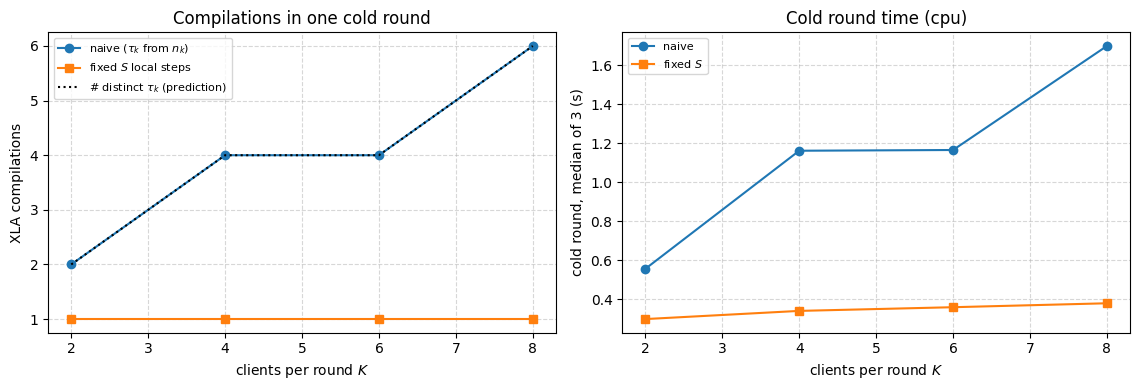

In [14]:
def client_sizes_for(K, seed=3):
    # Realistic-ish spread of client sizes -> a realistic spread of tau_k.
    return np.random.default_rng(seed).integers(BATCH, 12 * BATCH, size=K)


def cold_round(K, mode, seed=3):
    # Data is prepared first and NOT timed. Then jax.clear_caches() empties every compiled
    # program in the process -- a fresh function object alone is not enough, because XLA
    # reuses an identical computation compiled earlier. make_trainer() gives a fresh jit
    # cache, so _cache_size() is an honest count of this round's compilations.
    sizes = client_sizes_for(K, seed)
    batches = []
    for k in range(K):
        x, y = make_data(int(sizes[k]), jax.random.fold_in(jax.random.key(11), k), TEMPLATES)
        if mode == "naive":
            batches.append(pre_batch(x, y, BATCH, int(sizes[k] // BATCH)))
        else:
            batches.append(sample_batches(x, y, jax.random.fold_in(jax.random.key(12), k)))
    jax.block_until_ready(batches)
    jax.clear_caches()
    t = make_trainer()
    t0 = time.perf_counter()
    for xb, yb in batches:
        jax.block_until_ready(t(params0, bn0, xb, yb))
    return t._cache_size(), time.perf_counter() - t0


REPS = 3          # each repeat is cold again; report the MEDIAN time
Ks = [2, 4, 6, 8]
res = {}
for m in ("naive", "fixed"):
    res[m] = []
    for K in Ks:
        runs = [cold_round(K, m) for _ in range(REPS)]
        assert len({c for c, _ in runs}) == 1, "compile count must not vary across repeats"
        res[m].append((runs[0][0], float(np.median([t for _, t in runs]))))
# The exact prediction: the naive trainer compiles once per DISTINCT tau, no more, no less.
distinct = [len(set((client_sizes_for(K) // BATCH).tolist())) for K in Ks]

print(f"{'K':>4}  {'distinct tau':>13}  {'naive compiles':>15}  {'fixed compiles':>15}  "
      f"{'naive (s)':>10}  {'fixed (s)':>10}")
print(f"(times: median of {REPS} cold repeats, trainer only, on {jax.devices()[0].device_kind})")
print("-" * 80)
for i, K in enumerate(Ks):
    print(f"{K:>4}  {distinct[i]:>13}  {res['naive'][i][0]:>15}  {res['fixed'][i][0]:>15}  "
          f"{res['naive'][i][1]:>10.2f}  {res['fixed'][i][1]:>10.2f}")
match = all(res["naive"][i][0] == distinct[i] for i in range(len(Ks)))
print(f"\nnaive compiles == number of distinct tau values, exactly: {match}")

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.0))
ax[0].plot(Ks, [r[0] for r in res["naive"]], "o-", label="naive ($\\tau_k$ from $n_k$)")
ax[0].plot(Ks, [r[0] for r in res["fixed"]], "s-", label="fixed $S$ local steps")
ax[0].plot(Ks, distinct, "k:", label="# distinct $\\tau_k$ (prediction)")
ax[0].set_xlabel("clients per round $K$"); ax[0].set_ylabel("XLA compilations")
ax[0].set_title("Compilations in one cold round")
ax[0].legend(fontsize=8); ax[0].grid(True, ls="--", alpha=0.5)

ax[1].plot(Ks, [r[1] for r in res["naive"]], "o-", label="naive")
ax[1].plot(Ks, [r[1] for r in res["fixed"]], "s-", label="fixed $S$")
ax[1].set_xlabel("clients per round $K$"); ax[1].set_ylabel(f"cold round, median of {REPS} (s)")
ax[1].set_title(f"Cold round time ({jax.devices()[0].device_kind})")
ax[1].legend(fontsize=8); ax[1].grid(True, ls="--", alpha=0.5)
plt.tight_layout()

> **Observe:** The left panel confirms the prediction: the naive trainer compiles once per
> distinct $\tau_k$, while the fixed-$S$ trainer compiles once per process, as long as
> other argument signatures stay fixed. This behavior also applies on GPU nodes.
>
> The right panel shows the timing effect. Both $K=4$ and $K=6$ require four compilations
> and take similar time. Each point is the median of three cold-cache runs, timing only
> the trainer. Compilation dominates this tiny CPU example; GPU training will have a
> different balance, so treat the compile count as the main finding.
>
> The lesson: keep changing data values out of compiled shapes where possible. Fixed local
> steps stabilize the shape, while $n_k$ still determines the aggregation weight. This
> changes local epochs into local steps — an algorithmic choice you must report.


### BatchNorm and padded batches

Padding a batch and masking its loss is not enough with BatchNorm. Padded examples still
affect the batch mean and variance, changing how real examples are normalized. Masking the
loss happens too late.

Let us measure the effect.


In [15]:
x_real, y_real = CLIENT_DATA[0][0][:10], CLIENT_DATA[0][1][:10]        # 10 real examples
CAP = 16

# pad with zeros to a fixed capacity, and mask the loss so padding contributes nothing
x_pad = jnp.concatenate([x_real, jnp.zeros((CAP - 10,) + x_real.shape[1:])])
y_pad = jnp.concatenate([y_real, jnp.zeros((CAP - 10,), jnp.int32)])
mask = jnp.concatenate([jnp.ones(10), jnp.zeros(CAP - 10)])

def masked_loss(params, static, state, x, y, m):
    logits, state = batched_forward(eqx.combine(params, static), state, x)
    per_ex = optax.softmax_cross_entropy_with_integer_labels(logits, y)
    return jnp.sum(per_ex * m) / jnp.sum(m), state          # the mask IS applied

l_exact, _ = loss_fn(params0, static0, bn0, x_real, y_real)                 # 10 examples
l_masked, _ = masked_loss(params0, static0, bn0, x_pad, y_pad, mask)        # 16, 6 padded

print(f"loss on the 10 real examples          : {float(l_exact):.6f}")
print(f"loss on 16 padded, correctly masked   : {float(l_masked):.6f}")
print(f"difference                             : {abs(float(l_exact) - float(l_masked)):.6f}")
print(f"relative                               : "
      f"{abs(float(l_exact) - float(l_masked)) / abs(float(l_exact)):.2%}")
print()
print("The mask is right and the answer is still wrong. BatchNorm normalized the 10 real")
print("rows using statistics computed over 16 rows, 6 of which are zeros. The mask runs")
print("AFTER the corruption. This is a real bug people ship.")
print()

# Does it grow with the amount of padding? Same 10 real rows, more and more zero rows.
print(f"{'padded rows':>12}  {'pad fraction':>13}  {'relative loss error':>20}")
print("-" * 50)
for n_pad in [0, 2, 6, 10, 22, 54]:
    xp = jnp.concatenate([x_real, jnp.zeros((n_pad,) + x_real.shape[1:])])
    yp = jnp.concatenate([y_real, jnp.zeros((n_pad,), jnp.int32)])
    mp_ = jnp.concatenate([jnp.ones(10), jnp.zeros(n_pad)])
    lm, _ = masked_loss(params0, static0, bn0, xp, yp, mp_)
    err = abs(float(l_exact) - float(lm)) / abs(float(l_exact))
    print(f"{n_pad:>12}  {n_pad / (10 + n_pad):>13.0%}  {err:>20.2%}")
print("^ zero padding -> exact; the error grows with the padded fraction. A bias, not noise.")
print()

# The same check on a BN-free model: pad+mask is EXACT, as Week 4 promised.
mlp = eqx.nn.MLP(3 * IMG * IMG, N_CLASSES, 16, 1, key=jax.random.key(3))
mp, ms = eqx.partition(mlp, eqx.is_inexact_array)

def mlp_loss(p, x, y, m):
    logits = jax.vmap(lambda xi: eqx.combine(p, ms)(xi.reshape(-1)))(x)
    per_ex = optax.softmax_cross_entropy_with_integer_labels(logits, y)
    return jnp.sum(per_ex * m) / jnp.sum(m)

a = mlp_loss(mp, x_real, y_real, jnp.ones(10))
b = mlp_loss(mp, x_pad, y_pad, mask)
print(f"BN-free MLP: exact {float(a):.8f} vs padded+masked {float(b):.8f}  "
      f"-> |diff| = {abs(float(a) - float(b)):.2e}")
print("Exact to float precision. So pad+mask is a correct technique -- it is just not")
print("correct for a model with a BATCH-COUPLED layer in it, and BatchNorm is the")
print("canonical one. (This is the same coupling that forced an AllReduce per BN per")
print("step in Week 5, and that FedBN exploits in Week 11. One layer, three weeks of")
print("consequences.)")

loss on the 10 real examples          : 1.401282
loss on 16 padded, correctly masked   : 1.392276
difference                             : 0.009006
relative                               : 0.64%

The mask is right and the answer is still wrong. BatchNorm normalized the 10 real
rows using statistics computed over 16 rows, 6 of which are zeros. The mask runs
AFTER the corruption. This is a real bug people ship.

 padded rows   pad fraction   relative loss error
--------------------------------------------------
           0             0%                 0.00%
           2            17%                 0.20%
           6            38%                 0.64%
          10            50%                 0.90%
          22            69%                 1.23%
          54            84%                13.48%
^ zero padding -> exact; the error grows with the padded fraction. A bias, not noise.

BN-free MLP: exact 1.44147944 vs padded+masked 1.44147944  -> |diff| = 0.00e+00
Exact to float pre

> **Observe:** With 6 of 16 rows padded, masking changes the BatchNorm model's loss by
> about 0.6%. Without BatchNorm, it matches exactly in this test. The error grows with
> padding, reaching 13% at 84% padding here.
>
> BatchNorm couples examples through batch statistics, so masking the loss cannot undo
> padding's effect. This coupling also matters for sharding (Week 5) and per-example
> gradients (Week 12).
>
> Fixed $S$ and $B$ with resampling avoids the padded-batch problem — another reason to
> prefer option 1.


### 🔬 Exercise 3

**Exercise:** there is a third way to buy a compile per client, and it looks completely
innocent. A client needs to weight its own loss by $n_k/n$ before returning. Write it
two ways:

1. `weight` as a `static_argnums` argument (because "it's just a float, and it's constant
   for that client"),
2. `weight` as an ordinary traced argument.

Count the cache entries after 6 clients with 6 distinct weights. Version 1 is a *cost*
problem: it recompiles, but the answer is right. Then write a third version that is a
*correctness* problem — the function reads $n_k$ from an enclosing scope instead of taking
it as an argument (Week 4's closure trap) — and show what happens when $n_k$ changes.


In [16]:
# --- Reference solution (instructor: blank this out for students) ---

def make_weighted(static):
    # A factory again -- jax.jit(weighted) twice would share ONE cache and the whole
    # comparison would silently show identical numbers. (Ask how I know.)
    def weighted(params, x, y, weight):
        logits = jax.vmap(lambda xi: eqx.combine(params, ms)(xi.reshape(-1)))(x)
        return weight * optax.softmax_cross_entropy_with_integer_labels(logits, y).mean()
    return jax.jit(weighted, static_argnums=3) if static else jax.jit(weighted)

f_static = make_weighted(True)      # "it's just a float, and it's constant for that client"
f_traced = make_weighted(False)     # a scalar, traced

weights = (client_sizes / client_sizes.sum()).tolist()
xs, ys = CLIENT_DATA[0][0][:BATCH], CLIENT_DATA[0][1][:BATCH]

print(f"{'client':>7}  {'weight':>9}  {'static cache':>13}  {'traced cache':>13}")
print("-" * 48)
for k, w_ in enumerate(weights):
    jax.block_until_ready(f_static(mp, xs, ys, w_))
    jax.block_until_ready(f_traced(mp, xs, ys, w_))
    print(f"{k:>7}  {w_:>9.5f}  {f_static._cache_size():>13}  {f_traced._cache_size():>13}")

print(f"\nstatic_argnums: {f_static._cache_size()} compiles for {len(weights)} clients "
      f"-> one per DISTINCT VALUE, exactly as documented.")
print(f"traced        : {f_traced._cache_size()} compile, all {len(weights)} weights correct.")
print()
print("Version 1 is a COST problem, not a correctness one: static_argnums bakes the")
print("value in as a literal, but a new value keys a new compile, so you get the right")
print("answer expensively. The CORRECTNESS problem is its silent cousin -- n_k read from")
print("an enclosing scope instead of passed (Week 4's closure trap):")

n_k_closure = 100.0
@jax.jit
def weighted_closure(params, x, y):
    logits = jax.vmap(lambda xi: eqx.combine(params, ms)(xi.reshape(-1)))(x)
    return (n_k_closure / 600.0) * optax.softmax_cross_entropy_with_integer_labels(logits, y).mean()

l_a = float(weighted_closure(mp, xs, ys))
n_k_closure = 300.0                  # "next client, three times the data"
l_b = float(weighted_closure(mp, xs, ys))
print(f"    client A (n_k=100) -> {l_a:.6f}")
print(f"    client B (n_k=300) -> {l_b:.6f}   identical: {l_a == l_b}")
print(f"    cache size: {weighted_closure._cache_size()} -- no recompile, no error, and")
print("    EVERY client was silently weighted as if it had 100 examples. Your FedAvg is")
print("    now an unweighted mean. It still converges -- to the wrong objective, with every")
print("    client counted equally -- which is what makes it hard to catch.")
print("    If it can change, it is an argument.")

 client     weight   static cache   traced cache
------------------------------------------------
      0    0.11088              1              1
      1    0.19038              2              1
      2    0.07113              3              1
      3    0.26778              4              1
      4    0.14017              5              1
      5    0.21967              6              1

static_argnums: 6 compiles for 6 clients -> one per DISTINCT VALUE, exactly as documented.
traced        : 1 compile, all 6 weights correct.

Version 1 is a COST problem, not a correctness one: static_argnums bakes the
value in as a literal, but a new value keys a new compile, so you get the right
answer expensively. The CORRECTNESS problem is its silent cousin -- n_k read from
an enclosing scope instead of passed (Week 4's closure trap):
    client A (n_k=100) -> 0.232980
    client B (n_k=300) -> 0.232980   identical: True
    cache size: 1 -- no recompile, no error, and
    EVERY client was silent

---

## 6. Flower's strategy API — no Ray needed

A Flower strategy is a plain Python object. You can pass client results directly to
`FedAvg().aggregate_fit(...)` and get aggregated parameters back—without starting a
server or Ray.

Use this approach to test aggregation math quickly. Use `run_simulation` to test the
client/server lifecycle.

Four useful strategy hooks are:

| Method | Purpose |
|---|---|
| `configure_fit` | Select clients and set training options |
| `aggregate_fit` | Combine client updates |
| `configure_evaluate` | Select clients for evaluation |
| `aggregate_evaluate` | Combine evaluation results |

For Weeks 10–13, we will often call `aggregate_fit` directly to inspect and test aggregation.

Let's start with a simple check: clients with 10 and 30 examples return weights of 1 and 3.
FedAvg should return their weighted average:

$$\frac{10 \times 1 + 30 \times 3}{10 + 30} = 2.5.$$

In [17]:
from flwr.common import FitRes, Status, Code
from flwr.server.strategy import FedAvg

class DummyProxy:
    # Strategies only use the proxy as an identity token; nothing calls it here.
    def __init__(self, cid):
        self.cid = cid

def make_fitres(ndarrays, num_examples, metrics=None):
    return FitRes(status=Status(Code.OK, ""),
                  parameters=ndarrays_to_parameters(ndarrays),
                  num_examples=num_examples,
                  metrics=metrics or {})

# The textbook check: weights 10 and 30 on values 1.0 and 3.0
#   (10*1 + 30*3) / 40 = 100/40 = 2.5
strategy = FedAvg()
toy = [(DummyProxy("a"), make_fitres([np.array([1.0], np.float32)], 10)),
       (DummyProxy("b"), make_fitres([np.array([3.0], np.float32)], 30))]
agg, _ = strategy.aggregate_fit(1, toy, [])
print("hand-computed  (10*1 + 30*3)/40 =", (10 * 1.0 + 30 * 3.0) / 40)
print("FedAvg         aggregate_fit    =", parameters_to_ndarrays(agg)[0])
print("^ exact. FedAvg is num_examples-weighted. It is NOT a uniform mean, and if you")
print("  report num_examples=1 from every client (a common copy-paste), it becomes one.")

hand-computed  (10*1 + 30*3)/40 = 2.5
FedAvg         aggregate_fit    = [2.5]
^ exact. FedAvg is num_examples-weighted. It is NOT a uniform mean, and if you
  report num_examples=1 from every client (a common copy-paste), it becomes one.


In [18]:
# Now the real thing: 6 clients, the actual ResNet parameters, real n_k.
def fake_client_update(k):
    # Pretend client k trained: perturb theta_0 in a client-specific direction.
    kk = jax.random.fold_in(jax.random.key(77), k)
    noise = jax.tree.map(lambda a: 0.05 * jax.random.normal(jax.random.fold_in(kk, hash(a.shape) % 1000), a.shape),
                         params0)
    return jax.tree.map(lambda a, b: a + b, params0, noise)

client_params = [fake_client_update(k) for k in range(K_CLIENTS)]
results = [(DummyProxy(str(k)),
            make_fitres(params_to_ndarrays(client_params[k]), int(client_sizes[k]),
                        {"loss": 1.0 + 0.1 * k}))
           for k in range(K_CLIENTS)]

agg, metrics = FedAvg().aggregate_fit(1, results, [])
agg_params = ndarrays_to_params(template, parameters_to_ndarrays(agg))

# ---- verify against the formula, computed independently in JAX ----
w = jnp.asarray(client_sizes / client_sizes.sum())
manual = jax.tree.map(lambda *ls: sum(wi * li for wi, li in zip(w, ls)), *client_params)

maxdiff = max(float(jnp.max(jnp.abs(a - b)))
              for a, b in zip(jax.tree.leaves(agg_params), jax.tree.leaves(manual)))
uniform = jax.tree.map(lambda *ls: sum(ls) / len(ls), *client_params)
unif_gap = max(float(jnp.max(jnp.abs(a - b)))
               for a, b in zip(jax.tree.leaves(agg_params), jax.tree.leaves(uniform)))

print(f"clients      : {K_CLIENTS}, sizes {client_sizes.tolist()}, n = {int(client_sizes.sum())}")
print(f"weights n_k/n: {np.round(client_sizes / client_sizes.sum(), 4).tolist()}")
print()
print(f"max |FedAvg  -  sum_k (n_k/n) theta_k|  = {maxdiff:.3e}   <- MATCHES to float32")
print(f"max |FedAvg  -  uniform mean|           = {unif_gap:.3e}   <- DIFFERENT, as it must be")
print(f"\nflwr aggregated metrics: {metrics}")
print("(empty -- Flower will not average your metrics unless you give it a")
print(" fit_metrics_aggregation_fn. Silence here is a WARNING, not a success.)")

clients      : 6, sizes [53, 91, 34, 128, 67, 105], n = 478
weights n_k/n: [0.1109, 0.1904, 0.0711, 0.2678, 0.1402, 0.2197]

max |FedAvg  -  sum_k (n_k/n) theta_k|  = 1.192e-07   <- MATCHES to float32
max |FedAvg  -  uniform mean|           = 3.098e-02   <- DIFFERENT, as it must be

flwr aggregated metrics: {}
(empty -- Flower will not average your metrics unless you give it a
 fit_metrics_aggregation_fn. Silence here is a WARNING, not a success.)


> **Observe:** `FedAvg.aggregate_fit` matches $\sum_k \frac{n_k}{n}\theta_k$ within float32
> rounding error and differs from the uniform mean, as in Exercise 1.
>
> - **`num_examples` sets the aggregation weight.** Returning the same placeholder count
>   for every client silently changes FedAvg into a uniform mean.
> - **Metrics need an aggregation rule.** Without `fit_metrics_aggregation_fn`, Flower
>   warns and returns an empty metrics dict. In §7, we combine client mean losses using
>   the same example-count weights.

### Recording history

In Flower 1.32, `run_simulation` returns `None`, so there is no returned `History` object.
To plot a loss curve, record results in a `FedAvg` subclass—the same approach we will
extend in Weeks 10–13.

In [19]:
HISTORY = []      # module-level: the strategy runs in the driver process, so this works

class RecordingFedAvg(FedAvg):
    # The extension point for the rest of the course. Week 10 compresses `results`
    # here; Week 13 filters Byzantine clients out of it; today we just watch.
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        # Keep our own copy of theta_0: FedAvg.initialize_parameters sets
        # self.initial_parameters = None after handing it to the server.
        ip = kwargs.get("initial_parameters")
        self._prev = (None if ip is None else
                      np.concatenate([a.ravel() for a in parameters_to_ndarrays(ip)]))

    def aggregate_fit(self, server_round, results, failures):
        params, metrics = super().aggregate_fit(server_round, results, failures)
        if params is not None:
            nds = parameters_to_ndarrays(params)
            flat = np.concatenate([a.ravel() for a in nds])
            HISTORY.append({
                "round": server_round,
                "n_clients": len(results),
                "n_failures": len(failures),
                "n_examples": sum(r.num_examples for _, r in results),
                "param_norm": float(np.linalg.norm(flat)),
                # how far the global model moved this round: ||theta_r - theta_{r-1}||
                "step": (float(np.linalg.norm(flat - self._prev))
                         if self._prev is not None else np.nan),
                "loss": float(metrics.get("loss", np.nan)),
            })
            self._prev = flat
        return params, metrics


HISTORY.clear()
# Supply the metrics aggregator this time, so `loss` is a number rather than nan --
# and note that the right way to combine per-client losses is the SAME n_k weighting.
rec = RecordingFedAvg(fit_metrics_aggregation_fn=lambda ms: {
    "loss": float(np.average([m["loss"] for _, m in ms], weights=[n for n, _ in ms]))})
for r in (1, 2):
    rec.aggregate_fit(r, results, [])
for h in HISTORY:
    print(h)
print("\nSubclassing the strategy is the one hook that sees every client's update AND the")
print("aggregate. Learn it now; Weeks 10-13 live inside aggregate_fit.")

{'round': 1, 'n_clients': 6, 'n_failures': 0, 'n_examples': 478, 'param_norm': 5.859251499176025, 'step': nan, 'loss': 1.279497907949791}
{'round': 2, 'n_clients': 6, 'n_failures': 0, 'n_examples': 478, 'param_norm': 5.859251499176025, 'step': 0.0, 'loss': 1.279497907949791}

Subclassing the strategy is the one hook that sees every client's update AND the
aggregate. Learn it now; Weeks 10-13 live inside aggregate_fit.


### 🔬 Exercise 4

**Exercise:** partial participation, measured with the direct driver — no Ray, so you
can afford 200 trials.

Sample a fraction $C$ of the 6 clients uniformly at random, aggregate only those with
`FedAvg`, and measure $\|\theta_C - \theta_{\text{full}}\|$ over many trials. Plot mean
and spread against $C \in \{1/6, 2/6, \dots, 1\}$.

Then repeat with the client updates made **heterogeneous** (each client pulled in its own
direction) and compare. Which regime does partial participation hurt, and why is that the
regime cross-device FL actually operates in?


     IID clients: ||agg_C - agg_full|| at C=1/6 -> 1.7547, at C=1 -> 0.0000
 non-IID clients: ||agg_C - agg_full|| at C=1/6 -> 2.8723, at C=1 -> 0.0000

Both curves go to 0 at C=1 (sampling everyone IS full participation -- a good
sanity check that the harness is right). The non-IID curve sits far above the IID
one everywhere else: when clients disagree, WHICH clients you sampled changes the
answer, so partial participation injects variance proportional to the disagreement.
Cross-device FL runs at C ~ 0.001 with maximally non-IID clients -- the top-left
corner of this plot. Weeks 10-11 are about that corner.


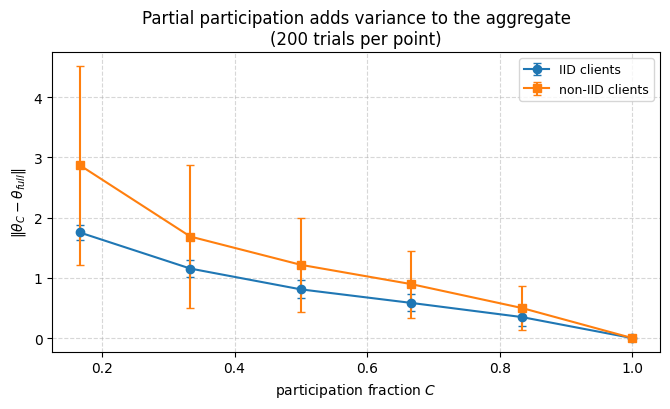

In [20]:
# --- Reference solution (instructor: blank this out for students) ---

def make_updates(heterogeneous, scale=0.05):
    out = []
    for k in range(K_CLIENTS):
        kk = jax.random.fold_in(jax.random.key(7), k)
        if heterogeneous:
            # each client pulls toward its OWN direction -> the aggregate depends on WHO showed up
            d = jax.tree.map(lambda a: scale * (k - 2.5) * jnp.ones_like(a), params0)
        else:
            d = jax.tree.map(
                lambda a: scale * jax.random.normal(jax.random.fold_in(kk, a.size % 997), a.shape),
                params0)
        out.append(jax.tree.map(lambda a, b: a + b, params0, d))
    return out

def aggregate(idx, ups):
    res = [(DummyProxy(str(k)), make_fitres(params_to_ndarrays(ups[k]), int(client_sizes[k])))
           for k in idx]
    # These clients report no metrics, so say so explicitly -- otherwise Flower logs a
    # 'No fit_metrics_aggregation_fn' warning on every one of the ~2,400 calls below.
    agg, _ = FedAvg(fit_metrics_aggregation_fn=lambda ms: {}).aggregate_fit(1, res, [])
    return np.concatenate([a.ravel() for a in parameters_to_ndarrays(agg)])

TRIALS = 200
Cs = np.arange(1, K_CLIENTS + 1) / K_CLIENTS
fig, ax = plt.subplots(figsize=(6.8, 4.2))

for het, style, lab in [(False, "o-", "IID clients"), (True, "s-", "non-IID clients")]:
    ups = make_updates(het)
    full = aggregate(range(K_CLIENTS), ups)
    means, stds = [], []
    r = np.random.default_rng(0)
    for C in Cs:
        m = max(1, int(round(C * K_CLIENTS)))
        ds = [np.linalg.norm(aggregate(r.choice(K_CLIENTS, m, replace=False), ups) - full)
              for _ in range(TRIALS)]
        means.append(np.mean(ds)); stds.append(np.std(ds))
    means, stds = np.array(means), np.array(stds)
    ax.errorbar(Cs, means, yerr=stds, fmt=style, capsize=3, label=lab)
    print(f"{lab:>16}: ||agg_C - agg_full|| at C=1/6 -> {means[0]:.4f}, at C=1 -> {means[-1]:.4f}")

ax.set_xlabel("participation fraction $C$")
ax.set_ylabel("$\\|\\theta_C - \\theta_{full}\\|$")
ax.set_title(f"Partial participation adds variance to the aggregate\n({TRIALS} trials per point)")
ax.legend(fontsize=9); ax.grid(True, ls="--", alpha=0.5)
plt.tight_layout()
print("\nBoth curves go to 0 at C=1 (sampling everyone IS full participation -- a good")
print("sanity check that the harness is right). The non-IID curve sits far above the IID")
print("one everywhere else: when clients disagree, WHICH clients you sampled changes the")
print("answer, so partial participation injects variance proportional to the disagreement.")
print("Cross-device FL runs at C ~ 0.001 with maximally non-IID clients -- the top-left")
print("corner of this plot. Weeks 10-11 are about that corner.")

---

## 7. Running clients with `run_simulation`

The §6 driver tests aggregation math. `run_simulation` adds the client/server lifecycle:
clients run in Ray worker processes, receive parameters, train locally, and return results.

|  | §6 driver | `run_simulation` |
|---|---|---|
| Execution | Current process | Ray worker processes |
| Client creation | Direct construction | `client_fn(context)` |
| Client identity | We pass `k` | `context.node_config["partition-id"]` |
| Data transfer | Direct Python calls | Serialized across processes |

Do not rely on client-object attributes surviving between calls. Manage persistent state
explicitly, and check `failures`: a simulation can continue even when clients fail.

Simulation tests process boundaries and client execution, but deployment still adds real
networks, devices, and failures.

### Trap: notebook-defined Equinox models

A model that works in a notebook may fail in a Ray worker. cloudpickle can reconstruct
notebook-defined classes differently from imported classes, breaking Equinox's class
machinery or PyTree registration. Possible errors include:

```
FrozenInstanceError: cannot assign to field 'conv'
TypeError: '_Missing' object is not subscriptable
```

The reliable approach is to:

1. Put the model and local-training code in a real `.py` module.
2. Make that module available on the workers' Python path before starting the simulation.
3. Exchange model parameters as NumPy arrays. (Here batch statistics are not sent: each
   worker starts from the module's initial `BN0`.)

This introduces the same packaging discipline used by a Flower App launched with
`flwr run`: workers must be able to import the code they execute.

In [21]:
# We are going to lift the code we already wrote and ran into a real .py file, so that
# there is exactly ONE definition of the model in this notebook -- the one you read in
# Section 3 -- and the workers import it rather than reconstructing it from bytecode.
#
# Even THIS needs a workaround, which is itself the lesson: inspect.getsource cannot see
# a CLASS defined in a notebook cell. inspect.getfile gives up the moment it sees
# __module__ == '__main__' with no file behind it, and a notebook has no file. Functions
# survive (their code object remembers the cell), classes do not. So we read the class
# back out of IPython's linecache by hand.
#
# In a real project this entire cell is replaced by: the file already exists.

def nb_source(obj):
    # inspect.getsource, but able to see classes defined in notebook cells.
    try:
        return inspect.getsource(obj)
    except OSError:
        pass
    files = {v.__code__.co_filename for v in vars(obj).values() if hasattr(v, "__code__")}
    for f in files:
        lines = linecache.getlines(f)
        for i, ln in enumerate(lines):
            if ln.startswith(f"class {obj.__name__}(") or ln.startswith(f"class {obj.__name__}:"):
                return "".join(inspect.getblock(lines[i:]))
    raise OSError(f"cannot recover source for {obj!r}")


TASK_DIR = tempfile.mkdtemp(prefix="hpml_w08_")
TASK_PY = pathlib.Path(TASK_DIR) / "fl_task.py"

HEADER = "\n".join([
    "import numpy as np", "import jax", "import jax.numpy as jnp",
    "import equinox as eqx", "import optax", "",
    f"N_CLASSES, IMG = {N_CLASSES}, {IMG}",
    f"BATCH, LOCAL_STEPS = {BATCH}, {LOCAL_STEPS}",
    "optimizer = optax.sgd(5e-2, momentum=0.9)", "",
])

# Built ONCE per worker process, at import: the static half of the model and the single
# compiled trainer that every round of every client on this worker reuses.
FOOTER = "\n".join([
    "", "_P0, STATIC, BN0 = build_model()",
    "TRAINER = make_trainer()      # ONE compile per worker, for ALL clients (§5)", "",
])

# These three exist in the notebook too, so fl_local_train below is runnable here as
# well as in a worker. In the module they come from FOOTER, built at import time.
_P0, STATIC, BN0 = build_model()
TRAINER = make_trainer()

def fl_local_train(params_nd, partition_id, server_round, n_clients):
    # THE CLIENT'S ENTIRE JOB. Runs in a worker process that shares nothing with the
    # notebook: it gets parameters (data) and an id (an int), and rebuilds the rest.
    params = ndarrays_to_params(_P0, params_nd)                  # treedef from LOCAL code

    templates = make_templates(jax.random.key(7))                # the shared task definition
    sizes = [53, 91, 34, 128, 67, 105]
    n_k = sizes[partition_id % len(sizes)]
    x, y = make_data(n_k, jax.random.fold_in(jax.random.key(5), partition_id), templates)

    # Week 4's PRNG design: (round, client) -> an independent, reproducible stream.
    # Derived from two ints. Never transmitted. (§3)
    ck = jax.random.fold_in(jax.random.fold_in(jax.random.key(2024), server_round), partition_id)
    xb, yb = sample_batches(x, y, ck)                            # FIXED shape -> ONE compile

    new_params, _, loss = TRAINER(params, BN0, xb, yb)
    # The optimizer state was created inside TRAINER and dies here: client-local (§3).
    # n_k is returned as the AGGREGATION WEIGHT, not as telemetry (§6).
    return params_to_ndarrays(new_params), int(n_k), float(loss)


SRC_OBJECTS = [ResBlock, ResNet, batched_forward, loss_fn, build_model,
               params_to_ndarrays, ndarrays_to_params, make_templates, make_data,
               sample_batches, make_trainer, fl_local_train]

body = "\n\n".join(nb_source(o) for o in SRC_OBJECTS)
# make_trainer closes over the notebook's `static0`; the module builds its own STATIC.
body = body.replace("static0", "STATIC")
TASK_PY.write_text(HEADER + body + FOOTER)

sys.path.insert(0, TASK_DIR)
os.environ["PYTHONPATH"] = TASK_DIR + os.pathsep + os.environ.get("PYTHONPATH", "")  # for Ray workers

import fl_task
print(f"wrote {TASK_PY}  ({len(TASK_PY.read_text().splitlines())} lines, "
      f"{len(SRC_OBJECTS)} objects lifted out of this notebook)")
print(f"importable as: {fl_task.__name__} from {fl_task.__file__}")
print()
# smoke-test it IN THIS PROCESS before we ever start Ray. Always do this: a bug here is
# 10 seconds to find, and 10 minutes inside a Ray traceback.
p0_nd, _, _ = fl_task.build_model()
nd, n_k, l = fl_task.fl_local_train(fl_task.params_to_ndarrays(p0_nd), 0, 0, 6)
print(f"smoke test: client 0 -> {len(nd)} tensors, n_k={n_k}, loss={l:.4f}   OK")

wrote /var/folders/zr/3ffdhrhj3vx2p15wftfylkr40000gp/T/hpml_w08_y4n8b9u7/fl_task.py  (149 lines, 12 objects lifted out of this notebook)
importable as: fl_task from /var/folders/zr/3ffdhrhj3vx2p15wftfylkr40000gp/T/hpml_w08_y4n8b9u7/fl_task.py

smoke test: client 0 -> 11 tensors, n_k=53, loss=1.4311   OK


Now the Flower app itself. Three objects: a `NumPyClient` (what a client *does*), a
`client_fn` (how a client is *born*), and a `server_fn` (what the server *is*).

Two warnings you will see, and should not paper over:

- **`run_simulation` prints a DEPRECATION warning** pointing at the `flwr run` CLI. It
  still works, and it is the right choice *in a notebook*, for the reason above: the CLI
  needs a Flower App project scaffold with a `pyproject.toml`, and a notebook cell cannot
  be one. You will see the warning. It is not a bug and it is not something to hide —
  when you move to the GPU node, you move to `flwr run`, and this notebook is the thing
  that taught you what the scaffold is *for*.
- **`min_available_clients=N` is not optional.** Leave it out and round 1 quietly samples
  fewer clients than later rounds, because the Ray workers have not all registered yet.
  Your round-1 numbers are then wrong in a way no error reports. Set it.


In [22]:
from flwr.client import ClientApp, NumPyClient
from flwr.server import ServerApp, ServerAppComponents, ServerConfig
from flwr.simulation import run_simulation
from flwr.common import Context

N_SUPERNODES = 6
N_ROUNDS = 3

class JaxFlowerClient(NumPyClient):
    # A "simulation client": constructed fresh each round, in a worker process, knowing
    # nothing but its partition id. Deliberately thin -- all the work is in fl_task.
    def __init__(self, partition_id, n_clients):
        self.partition_id = partition_id
        self.n_clients = n_clients

    def fit(self, parameters, config):
        # parameters: list[np.ndarray] straight off the wire.
        # return: (list[np.ndarray], num_examples, metrics)
        #         ^ num_examples is the AGGREGATION WEIGHT (see Section 6), not telemetry.
        nds, n_k, loss = fl_task.fl_local_train(parameters, self.partition_id,
                                                int(config.get("server_round", 0)),
                                                self.n_clients)
        return nds, n_k, {"loss": loss, "partition_id": float(self.partition_id)}


def client_fn(context: Context):
    # How a client learns who it is. This is the ONLY thing distinguishing the 6 workers.
    pid = int(context.node_config["partition-id"])
    return JaxFlowerClient(pid, N_SUPERNODES).to_client()


def weighted_loss(metrics):
    # n_k-weighted, for the same reason FedAvg's parameter average is (Section 6).
    ns = [n for n, _ in metrics]
    return {"loss": float(np.average([m["loss"] for _, m in metrics], weights=ns))}


def fit_config(server_round):
    return {"server_round": server_round}      # this is how the round number reaches a client


def server_fn(context: Context):
    p0, _, _ = fl_task.build_model()
    strategy = RecordingFedAvg(
        initial_parameters=ndarrays_to_parameters(fl_task.params_to_ndarrays(p0)),
        fraction_fit=1.0,
        min_fit_clients=N_SUPERNODES,
        min_available_clients=N_SUPERNODES,     # <- NOT optional; see the markdown above
        fraction_evaluate=0.0,
        on_fit_config_fn=fit_config,
        fit_metrics_aggregation_fn=weighted_loss,
    )
    return ServerAppComponents(strategy=strategy, config=ServerConfig(num_rounds=N_ROUNDS))


print(f"ClientApp : {N_SUPERNODES} supernodes, client_fn -> partition-id -> JaxFlowerClient")
print(f"ServerApp : RecordingFedAvg, {N_ROUNDS} rounds, fraction_fit=1.0")
print("The real lab runs 100 clients with fraction_fit=0.1 on the GPU node.")

ClientApp : 6 supernodes, client_fn -> partition-id -> JaxFlowerClient
ServerApp : RecordingFedAvg, 3 rounds, fraction_fit=1.0
The real lab runs 100 clients with fraction_fit=0.1 on the GPU node.


In [23]:
HISTORY.clear()

t0 = time.perf_counter()
ret = run_simulation(
    server_app=ServerApp(server_fn=server_fn),
    client_app=ClientApp(client_fn=client_fn),
    num_supernodes=N_SUPERNODES,
    backend_config={"init_args": {"num_cpus": 4,
                                  "log_to_driver": False,      # or Ray floods the notebook
                                  "include_dashboard": False}},
)
sim_wall = time.perf_counter() - t0

print(f"\nrun_simulation returned: {ret!r}   <- None. There is no History object in flwr "
      f"{flwr.__version__}.")
print(f"wall-clock: {sim_wall:.1f} s for {N_SUPERNODES} clients x {N_ROUNDS} rounds "
      f"on {jax.devices()[0].device_kind}")
print("\nHISTORY, captured by our RecordingFedAvg subclass:")
print(f"{'round':>6}  {'clients':>8}  {'failures':>9}  {'n_examples':>11}  {'loss':>9}  {'||theta||':>10}  {'step':>8}")
print("-" * 74)
for h in HISTORY:
    print(f"{h['round']:>6}  {h['n_clients']:>8}  {h['n_failures']:>9}  "
          f"{h['n_examples']:>11}  {h['loss']:>9.4f}  {h['param_norm']:>10.4f}  {h['step']:>8.4f}")

INFO :      Starting Flower ServerApp, config: num_rounds=3, no round_timeout
INFO :      
INFO :      [INIT]
INFO :      Using initial global parameters provided by strategy
INFO :      Starting evaluation of initial global parameters
INFO :      Evaluation returned no results (`None`)
INFO :      
INFO :      [ROUND 1]
INFO :      configure_fit: strategy sampled 6 clients (out of 6)
/Users/Shinhoo/.pyenv/versions/3.11.0/lib/python3.11/subprocess.py:1832: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = _fork_exec(
INFO :      aggregate_fit: received 6 results and 0 failures
INFO :      configure_evaluate: no clients selected, skipping evaluation
INFO :      
INFO :      [ROUND 2]
INFO :      configure_fit: strategy sampled 6 clients (out of 6)
INFO :      aggregate_fit: received 6 results and 0 failures
INFO :      configure_evaluate: no clients selected, skipping ev


run_simulation returned: None   <- None. There is no History object in flwr 1.20.0.
wall-clock: 19.1 s for 6 clients x 3 rounds on cpu

HISTORY, captured by our RecordingFedAvg subclass:
 round   clients   failures   n_examples       loss   ||theta||      step
--------------------------------------------------------------------------
     1         6          0          478     1.4534      5.7706    0.2355
     2         6          0          478     1.3478      5.7702    0.1825
     3         6          0          478     1.3111      5.7801    0.1513


n_examples per round: {478}  <- identical every round: all 6 clients
                        participated every round (C=1.0), and the sum is n = 478.
failures: 0


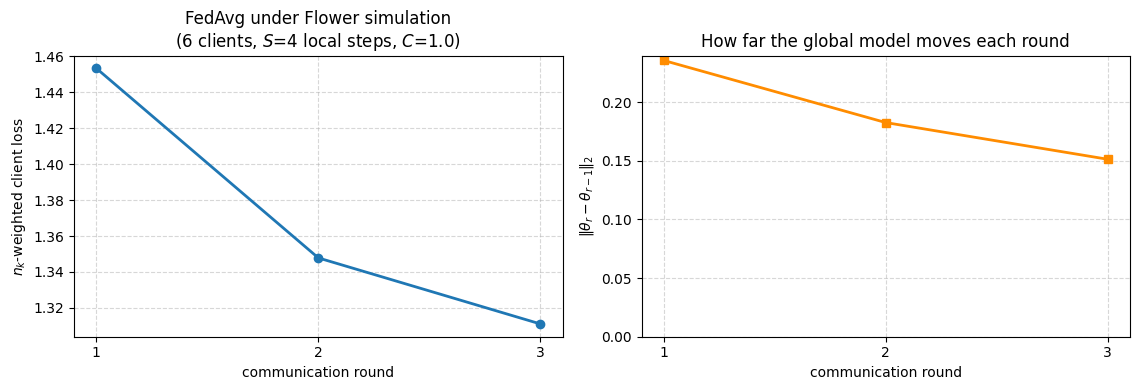

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.0))
rounds = [h["round"] for h in HISTORY]

ax[0].plot(rounds, [h["loss"] for h in HISTORY], "o-", lw=2)
ax[0].set_xlabel("communication round"); ax[0].set_ylabel("$n_k$-weighted client loss")
ax[0].set_title(f"FedAvg under Flower simulation\n({N_SUPERNODES} clients, "
                f"$S$={LOCAL_STEPS} local steps, $C$=1.0)")
ax[0].set_xticks(rounds)
ax[0].grid(True, ls="--", alpha=0.5)

# Plot the per-round step, not ||theta||: the norm can stay flat while theta moves a lot.
ax[1].plot(rounds, [h["step"] for h in HISTORY], "s-", lw=2, color="darkorange")
ax[1].set_xlabel("communication round")
ax[1].set_ylabel("$\\|\\theta_r - \\theta_{r-1}\\|_2$")
ax[1].set_title("How far the global model moves each round")
ax[1].set_ylim(bottom=0)
ax[1].set_xticks(rounds)
ax[1].grid(True, ls="--", alpha=0.5)
plt.tight_layout()

n_ex = {h["n_examples"] for h in HISTORY}
print(f"n_examples per round: {n_ex}  <- identical every round: all {N_SUPERNODES} clients")
print(f"                        participated every round (C=1.0), and the sum is n = "
      f"{sum(client_sizes)}.")
print(f"failures: {sum(h['n_failures'] for h in HISTORY)}")

> **Observe:** it ran. Six Equinox clients, in six Ray worker processes, each rebuilding
> the model from imported code, each doing $S = 4$ local SGD steps on its own synthetic
> shard, each reporting its own $n_k$, aggregated by a `FedAvg` subclass that we wrote and
> that we can now put anything into. **That is Stage 4 open.** Week 9 changes exactly one
> thing — the local objective gets a proximal term (FedProx), or the client gets a control
> variate (SCAFFOLD) — and everything you are looking at here stays put.
>
> Read the numbers carefully, though, because two of them are honest and one is not:
>
> - The **loss curve** moves in the right direction over three rounds, but three rounds of
>   a $\sim$1,600-parameter ResNet on synthetic templates is not evidence of anything.
>   It is a **plumbing check**: parameters left the server, changed, came back, and were
>   averaged. Do not put this plot in a paper.
> - **`n_examples` is identical every round and equals $n = \sum_k n_k$**, which *is* a
>   real check and a valuable one: it proves all 6 clients participated in every round,
>   including round 1. That is `min_available_clients` doing its job. Delete it and watch
>   round 1's number drop below the others while nothing complains.
> - The **wall-clock is meaningless** and does not belong in a report. Most of it is Ray
>   spinning up workers and each worker importing JAX from scratch — a fixed cost this
>   notebook pays six times and a real deployment does not pay at all.


### Simulation client vs physical client — what the rehearsal still hides

`run_simulation` bought us process isolation, real serialization, and a real lifecycle.
It is not a deployment, and it is worth being precise about the gap, because your
proposal's threat model and cost model both depend on it:

- **Wall-clock is fiction.** Six workers time-slicing eleven CPU cores is not six phones.
  Any "FL is $X\times$ slower" claim from a simulation is a claim about your laptop.
  Report **rounds**, **bytes**, and **local steps** — the units that survive the move to
  hardware. (This is the same discipline as Week 5: count bytes here, measure seconds
  there.)
- **Stragglers do not exist.** Ray returns when the work is done. Real clients drop out
  mid-round, run 10× slower, and lose network. That is systems heterogeneity, it is
  Week 10's subject, and you have to *inject* it into a simulation on purpose.
- **The `failures` list is always empty here.** In deployment it is not, and a strategy
  that ignores `failures` is a strategy that has never been deployed.
- **Nobody is lying to you.** Every client returns an honest update. Weeks 12–13 remove
  that assumption, and note *where* they will do it: inside `aggregate_fit`, which is
  precisely the seam we just built.
- **The data is yours.** You made all six shards, so you can look at them. The defining
  constraint of real FL — that you *cannot inspect the data* — is the one thing a
  simulation can never impose on you. Guard against it deliberately: if your method needs
  to peek at the union of the clients' data to work, it does not work.


---

## 8. Proposal scaffold: a reproducible FL experiment

There is no graded lab this week. The deliverable is the **project proposal** — a 5–7
minute lightning talk plus a document, **20% of the grade**. So this section is the
lab-shaped thing: the smallest harness that makes an FL claim *reproducible*, which you
can lift directly into your proposal.

An FL result is a claim of the form:

> *Under partition $\mathcal{P}$, with $K$ clients at participation $C$, algorithm $A$
> reaches metric $M$ within $R$ rounds and $B$ bytes.*

Every one of those seven symbols is a knob, and a result that does not pin all seven is
not reproducible. Most FL papers are not reproducible for exactly this reason: they
report $M$ and $R$ and quietly leave $\mathcal{P}$, $C$, and $B$ to the reader's
imagination. Your proposal can clear that bar with a dataclass.


In [25]:
import dataclasses
import json

@dataclasses.dataclass(frozen=True)
class FLConfig:
    # --- the task -------------------------------------------------------------
    dataset: str = "cifar10"          # the notebook uses a synthetic stand-in
    model: str = "resnet8"
    # --- the federation (P, K, C) --------------------------------------------
    n_clients: int = 100
    partition: str = "dirichlet"      # "iid" | "dirichlet" | "shard"
    dirichlet_alpha: float = 0.5      # THE non-IID knob. Report it or the result is void.
    participation: float = 0.1        # C
    # --- the algorithm (A) ----------------------------------------------------
    algorithm: str = "fedavg"         # "fedavg" | "fedprox" | "scaffold" | ...
    local_steps: int = 4              # S -- fixed for everyone (Section 5!)
    batch_size: int = 16
    client_lr: float = 0.05
    client_momentum: float = 0.9
    server_lr: float = 1.0            # 1.0 == plain FedAvg; != 1.0 == FedAvgM/FedOpt
    # --- the budget (R, B) ----------------------------------------------------
    rounds: int = 3
    # --- reproducibility ------------------------------------------------------
    seed: int = 0

    def bytes_per_round(self, n_params):
        # The number your communication plot needs. Compute it; do not estimate it.
        return int(round(self.participation * self.n_clients) * 2 * n_params * 4)

    def fingerprint(self):
        import hashlib
        s = json.dumps(dataclasses.asdict(self), sort_keys=True)
        return hashlib.sha1(s.encode()).hexdigest()[:10]


cfg = FLConfig(n_clients=N_SUPERNODES, participation=1.0, rounds=N_ROUNDS,
               local_steps=LOCAL_STEPS, batch_size=BATCH, partition="dirichlet",
               dirichlet_alpha=0.5)

n_params = int(flat_params.size)
print(f"config fingerprint : {cfg.fingerprint()}   <- put this in your filename")
print(f"model parameters   : {n_params:,}")
print(f"bytes / round      : {cfg.bytes_per_round(n_params) / 1024:.1f} KiB "
      f"(C={cfg.participation} x K={cfg.n_clients} x 2 x |theta| x 4B)")
print(f"total budget       : {cfg.rounds * cfg.bytes_per_round(n_params) / 1024:.1f} KiB "
      f"over {cfg.rounds} rounds")
print()
real = FLConfig()      # what the GPU node actually runs
print(f"the real lab: K={real.n_clients}, C={real.participation}, alpha={real.dirichlet_alpha}, "
      f"R={real.rounds}")
print(f"              {real.bytes_per_round(25_000_000) / 1e9:.2f} GB/round for a "
      f"ResNet-50 -- now go read Week 10.")
print()
print(json.dumps(dataclasses.asdict(cfg), indent=2)[:340] + " ...")
print("\nEvery run writes this dict next to its results. A result whose config you cannot")
print("reconstruct is an anecdote.")

config fingerprint : 3368175430   <- put this in your filename
model parameters   : 1,452
bytes / round      : 68.1 KiB (C=1.0 x K=6 x 2 x |theta| x 4B)
total budget       : 204.2 KiB over 3 rounds

the real lab: K=100, C=0.1, alpha=0.5, R=3
              2.00 GB/round for a ResNet-50 -- now go read Week 10.

{
  "dataset": "cifar10",
  "model": "resnet8",
  "n_clients": 6,
  "partition": "dirichlet",
  "dirichlet_alpha": 0.5,
  "participation": 1.0,
  "algorithm": "fedavg",
  "local_steps": 4,
  "batch_size": 16,
  "client_lr": 0.05,
  "client_momentum": 0.9,
  "server_lr": 1.0,
  "rounds": 3,
  "seed": 0
} ...

Every run writes this dict next to its results. A result whose config you cannot
reconstruct is an anecdote.


### The Dirichlet partition — the one knob everyone reports and few define

`partition="dirichlet"` above needs a definition, because "non-IID" is not one thing
(Week 11 taxonomizes it: label skew, feature skew, quantity skew, concept drift). The
standard label-skew benchmark draws each client's class mixture from
$\text{Dir}(\alpha)$: $\alpha \to \infty$ is IID, $\alpha \to 0$ is one class per client.

You will need this in Weeks 9–11 and probably in your project. Build it once, here.


no min_size guard:
  alpha=100.0: smallest client has  187 examples, 0 client(s) got ZERO
  alpha=  1.0: smallest client has   53 examples, 0 client(s) got ZERO
  alpha=  0.1: smallest client has    0 examples, 1 client(s) got ZERO
  ^ at alpha=0.1 with only 4 classes, some clients are dealt nothing at all.
    That is not 'very non-IID', it is a broken partition. Hence the guard:

with min_size=20:
  alpha   redraws          sizes   imbalance   classes/client   >50% one class
----------------------------------------------------------------------------------
  100.0         1    187-  219        1.2x        4-4                 0 of 10
    1.0         1     53-  377        7.1x        3-4                 2 of 10
    0.1        38     25-  485       19.4x        1-3                10 of 10

'classes/client' counts classes holding >=5% of that client's data (a class you
have 3 examples of is not a class you have). '>50% one class' counts clients
dominated by a single label -- the number t

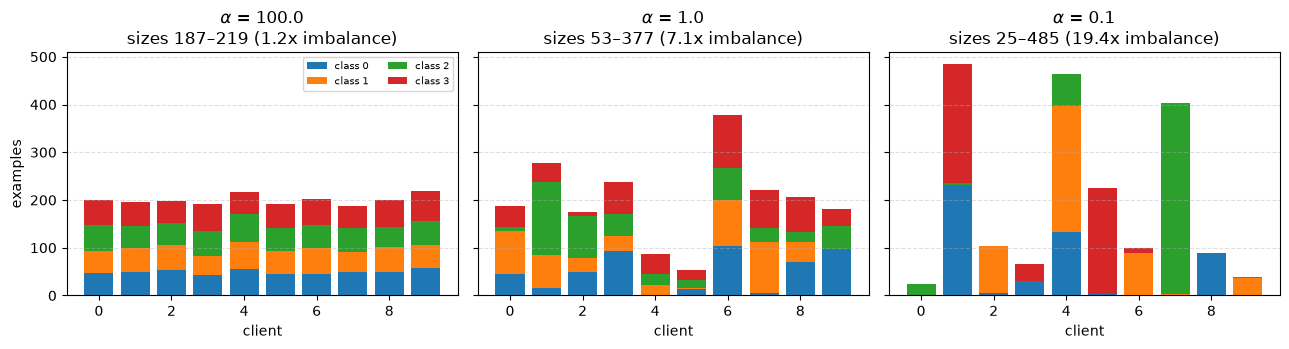

In [26]:
def dirichlet_partition(labels, n_clients, alpha, seed=0, min_size=0, max_tries=200):
    # Standard label-skew benchmark: for each CLASS, split its indices across clients
    # with proportions drawn from Dir(alpha). Small alpha -> a client owns few classes.
    #
    # min_size: the guard that every real implementation has and no paper mentions.
    # At small alpha a client can be dealt ZERO examples, which is not "extreme non-IID",
    # it is a degenerate client that will crash your training loop. The standard fix is
    # to redraw the whole partition until every client clears a floor.
    labels = np.asarray(labels)
    for t in range(max_tries):
        r = np.random.default_rng(seed + 1000 * t)
        idx_by_client = [[] for _ in range(n_clients)]
        for c in np.unique(labels):
            idx_c = np.where(labels == c)[0]
            r.shuffle(idx_c)
            p = r.dirichlet(np.repeat(alpha, n_clients))
            cuts = (np.cumsum(p) * len(idx_c)).astype(int)[:-1]
            for k, part in enumerate(np.split(idx_c, cuts)):
                idx_by_client[k].extend(part.tolist())
        parts = [np.array(sorted(ix)) for ix in idx_by_client]
        if min(len(p_) for p_ in parts) >= min_size:
            return parts, t + 1
    return parts, max_tries


X_all, Y_all = make_data(2000, jax.random.key(42), TEMPLATES)
Y_np = np.asarray(Y_all)
alphas = [100.0, 1.0, 0.1]

# First: what happens with NO guard?
print("no min_size guard:")
for alpha in alphas:
    parts, _ = dirichlet_partition(Y_np, 10, alpha, seed=0, min_size=0)
    sizes = np.array([len(p_) for p_ in parts])
    print(f"  alpha={alpha:>5}: smallest client has {sizes.min():>4} examples, "
          f"{int((sizes == 0).sum())} client(s) got ZERO")
print("  ^ at alpha=0.1 with only 4 classes, some clients are dealt nothing at all.")
print("    That is not 'very non-IID', it is a broken partition. Hence the guard:")
print()

MIN_SIZE = 20
fig, ax = plt.subplots(1, len(alphas), figsize=(13, 3.6), sharey=True)
print(f"with min_size={MIN_SIZE}:")
print(f"{'alpha':>7}  {'redraws':>8}  {'sizes':>13}  {'imbalance':>10}  {'classes/client':>15}  "
      f"{'>50% one class':>15}")
print("-" * 82)
for a, alpha in zip(ax, alphas):
    parts, tries = dirichlet_partition(Y_np, 10, alpha, seed=0, min_size=MIN_SIZE)
    mat = np.zeros((10, N_CLASSES))
    for k, ix in enumerate(parts):
        for c in range(N_CLASSES):
            mat[k, c] = np.sum(Y_np[ix] == c)
    bottom = np.zeros(10)
    for c in range(N_CLASSES):
        a.bar(np.arange(10), mat[:, c], bottom=bottom, label=f"class {c}")
        bottom += mat[:, c]
    sizes = mat.sum(axis=1)
    # "effective" classes: how many classes a client really has, not how many it has >=1 of
    dominant = (mat.max(axis=1) / np.maximum(sizes, 1))
    eff = np.array([int(np.sum(mat[k] >= 0.05 * max(sizes[k], 1))) for k in range(10)])
    a.set_title(f"$\\alpha$ = {alpha}\nsizes {int(sizes.min())}–{int(sizes.max())} "
                f"({sizes.max() / max(sizes.min(), 1):.1f}x imbalance)")
    a.set_xlabel("client"); a.grid(True, ls="--", alpha=0.4, axis="y")
    print(f"{alpha:>7}  {tries:>8}  {int(sizes.min()):>5}-{int(sizes.max()):>5}  "
          f"{sizes.max() / max(sizes.min(), 1):>9.1f}x  {eff.min():>7}-{eff.max():<7}  "
          f"{int(np.sum(dominant > 0.5)):>10} of 10")
ax[0].set_ylabel("examples"); ax[0].legend(fontsize=7, ncol=2)
plt.tight_layout()
print("\n'classes/client' counts classes holding >=5% of that client's data (a class you")
print("have 3 examples of is not a class you have). '>50% one class' counts clients")
print("dominated by a single label -- the number that actually tracks how hard FL is.")

> **Observe:** one parameter produces the whole spectrum. At $\alpha = 100$ every client
> holds all four classes in near-equal proportion and the sizes barely differ — that is
> the IID setting, and it is where FedAvg looks great. As $\alpha$ falls, clients become
> **dominated by a single label** and their sizes spread out, so **you get label skew and
> quantity skew together**.
>
> Three things this exercise should leave you suspicious about:
>
> - **The un-guarded partition deals some clients zero examples.** That is not "extreme
>   non-IID", it is a broken benchmark, and the `min_size` redraw loop that every real
>   implementation carries is *nowhere in the papers that cite them*. Our guard needed
>   several redraws at $\alpha = 0.1$ — meaning the partition you actually train on is
>   **conditioned on not being too skewed**, which is a quiet thumb on the scale that
>   nobody reports.
> - **$\alpha$ alone does not specify an experiment.** Its effect depends on $K$ and on
>   the number of classes: with 4 classes and 10 clients, $\alpha = 0.1$ cannot help but
>   starve someone. Two papers both reporting "$\alpha = 0.5$" can be running visibly
>   different experiments. Report $\alpha$, **$K$, the class count, the min-size guard,
>   and the seed**.
> - **$\alpha$ reproduces Exercise 1's two failures at once**: unequal $n_k$ (which the
>   $n_k/n$ weight fixes) and client disagreement (which it does not). So when your
>   $\alpha = 0.1$ run underperforms there are two candidate causes, and §2 taught you how
>   to tell them apart. Do not report the first as the second.
>
> The partition **is** the experiment. A non-reproducible partition is a non-reproducible
> result, whatever the accuracy column says.


---

## Summary

Stage 4 is open: the same Equinox/Optax codebase from Weeks 3–7, unchanged in its
mathematics, now running under a real Flower simulation with six clients in six
processes.

- **FL is a governance decision before it is a bandwidth optimization** (§1). The
  arithmetic is unambiguous: at cross-device scale a *single* round of federated
  ResNet-50 across 1% of a million phones moves more bytes than centralizing every photo
  once. You do it anyway, because the centralized dataset is not allowed to exist. In
  cross-silo the bandwidth argument does hold. Know which one you are in, and **do not
  claim the motivation you have not computed**.
- **FL is Local SGD minus its assumptions** (§2). The $\tau=1$ identity is exact; FL is
  what you get by dropping IID data, equal $n_k$, full participation, homogeneous
  workers, trust, and the ability to *look at your own data*. Exercise 1 separated the
  two failures people conflate: the $n_k/n$ weight fixes **size imbalance** and does
  **nothing** for **client drift** — the curves for weighted and uniform lie exactly on
  top of each other once the sizes are equal. Do not diagnose drift when you have a
  bookkeeping bug, and do not expect bookkeeping to fix drift.
- **The four states finally earn their separation** (§3). Parameters cross both ways;
  the optimizer state is client-local and **discarded every round** (shipping it is a
  free $2$–$3\times$ on your dominant cost — and we measured the client momenta pointing
  in genuinely different directions, because momentum describes a trajectory that ends
  when the round does); batch stats are *data statistics*, not parameters, which is why
  FedBN can keep them local; PRNG is derived from `fold_in(round, cid)` and never
  transmitted.
- **The transport boundary is leaves-only, and order is the entire contract** (§4). The
  round trip is **bitwise exact** — not "close to 1e-7"; if it is merely close, something
  is casting. The treedef never crosses: both sides rebuild it from `build_model()`. The
  failure to fear is silent — two same-shaped tensors swapped give you a valid model with
  the wrong weights, no exception, and a week spent blaming client drift.
- **The recompilation trap is Week 4's debt, and it is the most useful thing here** (§5).
  Letting $\tau_k = \lfloor n_k/B \rfloor$ makes a **property of the data** into a
  **property of the program**: one compile per **distinct $\tau_k$**, which the sweep
  confirmed exactly — up to $K$, and again in every Ray worker process. Fixing $S$ local
  steps for everyone pinned it at **1, for any $K$**, and the heterogeneity moved to
  where it belonged — the traced float $n_k/n$. **Numbers are traced; shapes are baked;
  put your heterogeneity in the numbers.** And a trap inside the fix:
  pad+mask is *bitwise* exact on a BN-free model and **biased** with BatchNorm, because BN
  normalizes over the padding before the mask can run.
- **The strategy API needs no Ray** (§6). `FedAvg.aggregate_fit` reproduced
  $\sum_k \frac{n_k}{n}\theta_k$ to float32, driven by hand in microseconds. Develop
  aggregation there. And **`num_examples` is the aggregation weight, not telemetry** —
  return a placeholder and FedAvg silently becomes the uniform mean that Exercise 1
  showed to be badly wrong.
- **`run_simulation` is the lifecycle rehearsal** (§7), and it enforces the two things
  the in-process driver grants you for free: your client code must be **importable** (an
  Equinox `Module` cloudpickled by value raises `FrozenInstanceError` from its own
  `__init__` — which is *why* the production tool is `flwr run` against a real package),
  and your client must rebuild everything from parameters + an ID. What it still hides:
  wall-clock, stragglers, failures, adversaries, and the fact that you cannot look at the
  data.
- **A reproducible FL claim pins seven symbols** (§8): partition $\mathcal{P}$ (and
  $\alpha$), $K$, $C$, algorithm $A$, metric $M$, rounds $R$, bytes $B$. That is your
  proposal, and a dataclass is a perfectly respectable way to say it.

**The thread.** Week 7 proved FedAvg and Local SGD are the same update. Today made that
true in *code* — the identical Equinox model, the identical Optax optimizer, the
identical four states, now moving through Flower. Everything from here changes exactly
one thing at a time and everything else stays where it is. Week 9 changes the client's
**objective** (FedProx's proximal term, SCAFFOLD's control variate) and attacks the drift
Exercise 1 isolated. Week 10 changes what `aggregate_fit` **receives** (quantized,
sparsified, from a sampled $C$-slice) and attacks the byte count §1 computed. Weeks 12–13
change who you can **trust** inside that same `aggregate_fit`. The seam is built. Bring
your proposal.

### Further Exercises

1. **The bandwidth crossover, for your project.** Redo §1's calculation with *your*
   proposal's $K$, $n_k$, $C$, and $|\theta|$. At what round does FL overtake
   centralizing? Now apply Week 10's 8-bit quantization ($4\times$) and top-1%
   sparsification ($100\times$ on the upload only — why only the upload?) and recompute.
   Does your project's motivation survive its own arithmetic?
2. **Break `min_available_clients`.** Delete it from `server_fn`, rerun §7, and print
   `n_clients` per round from `HISTORY`. Show round 1 sampling fewer clients than later
   rounds, and note that nothing raised. Then explain what that does to a round-1 data
   point in a paper, and write the assertion you should have had.
3. **The bucketing middle ground.** Implement §5's option 2: pad $\tau_k$ to the next
   power of two and mask the padded *steps* (not examples — why is that safe with
   BatchNorm when padding examples is not?). Plot compiles vs $K$ for all three options
   and confirm the $\log$ scaling. When is bucketing the right answer over fixed $S$?
4. **Make a client fail.** Have client 3 raise an exception in `fit()`. Show that
   `run_simulation` survives, that the exception lands in `aggregate_fit`'s `failures`
   list, and that FedAvg **silently aggregates the other five** — including the $n_k/n$
   weights renormalizing over the survivors. Is that the behaviour you want? Now set
   `accept_failures=False` and compare. This is Week 13's opening move.
5. **Local epochs vs local steps.** §5 changed the algorithm to remove a compile. Quantify
   what that cost: run FedAvg with $\tau_k = \lfloor n_k/B \rfloor$ (epochs) against fixed
   $S$ (steps) on a Dirichlet-$0.1$ partition for 30 rounds and compare accuracy-vs-round.
   Under `alpha=0.1` the client sizes are wildly unequal, so "one epoch" gives big clients
   many more steps than small ones. Is that a feature or a bug? Argue both sides — this is
   a live disagreement in the literature.
6. **Port the harness to `flwr run`.** Turn §7's `fl_task.py` plus the two apps into a
   real Flower App: `flwr new`, fill in `pyproject.toml`, and run it with `flwr run` on
   the GPU node with 100 clients and CIFAR-10 through Grain. Compare the wall-clock and
   explain which parts of §7's timing were artifacts of the notebook. This is the bridge
   to your project's actual infrastructure.
